# Modelos de aprendizaje automático y comunicación de resultados
## Rendimiento de los cultivos del Valle del Cauca y su relación con la temperatura (IDEAM)

**Asignatura:** Ciencia de Datos con Python (IGS38) · Universidad Santiago de Cali

**Caso de estudio:** Analítica de datos abiertos de Colombia con datos.gov.co

**Parte 3:** Modelos de aprendizaje automático y comunicación de resultados (RA5 y RA6)

**Autor:** Juan David Muñoz Sotelo

Este notebook toma la **tabla integrada de la Parte 2** (`cultivos_temperatura.csv`) y la usa para responder con modelos la pregunta del proyecto: *¿se puede predecir mejor el rendimiento de un cultivo si se conoce cuánto se desvió la temperatura de su municipio respecto a lo normal?*

## Pregunta e hipótesis

**Pregunta.** ¿Cómo ha evolucionado el rendimiento de los principales cultivos del Valle del Cauca a lo largo del tiempo y qué relación existe entre sus variaciones y la temperatura registrada en los municipios donde se producen?

**Pregunta de la Parte 3, en términos de modelo.** ¿Un modelo que conoce la anomalía térmica del año (y del año anterior) predice el rendimiento relativo de un cultivo **mejor que uno que no la conoce**, cuando se evalúa en años que no vio al entrenar?

### Mapa de hipótesis: dónde se responde cada una

Las cinco hipótesis (H1 a H5) nacen del análisis exploratorio del Laboratorio 2. **Se responden las cinco, y cada una recibe dos pruebas independientes**:

1. una **prueba estadística de asociación** (sección 9, 9.1 y 9.2), con las anomalías originales de la Parte 2;
2. una **prueba con modelo de aprendizaje automático** (secciones 5 a 8 y 9.3), con variables recalculadas sin fuga y evaluadas en años que el modelo no vio.

| Hipótesis (Laboratorio 2) | Prueba estadística | Prueba con modelo | Variable de la integración |
|---|---|---|---|
| **H1.** Año más cálido que lo normal → menor rendimiento relativo | Regresión con errores agrupados y Holm (sec. 9) · Mann-Whitney cálidos vs fríos (sec. 9) · efectos fijos por municipio-cultivo (9.2) | **M2 vs M1** con *bootstrap* (sec. 7) · ablación sin `t_anom` (9.3) · signo del coeficiente de M5 (5.4) | `t_anomalia` |
| **H2.** La asociación negativa es más fuerte en transitorios | Interacción `t_anomalia × transitorio` (sec. 9) · pendientes por grupo (9.2) | Error por grupo (7.1) · ΔMAE de M2 vs M1 solo en transitorios y solo en permanentes (9.3) | `t_anomalia`, `grupo` |
| **H3.** Un año cálido pesa más en municipios cálidos | Interacción `t_anomalia × clima` (sec. 9) · pendientes por clima y **Kruskal-Wallis** (9.2) | Error por clima (7.1) · ΔMAE de M2 vs M1 por clima (9.3) | `t_anomalia`, `clima_municipio` |
| **H4.** La temperatura del año anterior también se asocia, sobre todo en permanentes | Interacción `t_anomalia_prev × permanente` (sec. 9) · aporte del rezago por grupo, ΔR² (9.2) | Ablación sin `t_anom_prev` (9.3) · importancia por permutación (8) | `t_anomalia_prev` |
| **H5.** Más amplitud térmica que la normal → menor rendimiento | Regresión con `amplitud_anomalia` (sec. 9) · correlación de Spearman (9.2) | **Gradient boosting** con `t_anom` y `amp_anom`: permutación y SHAP (8) · ablación sin `amp_anom` (9.3) | `amplitud_anomalia` |

**El taller pide entrenar al menos un modelo que responda a una hipótesis usando una variable de la integración y compararlo con una línea base.** Ese modelo es **M2** (*gradient boosting* con el clima completo), que responde de frente a **H1 y H5**, y por extensión a H2, H3 y H4 al mirarlo por grupo y por variable. Se compara con cuatro referencias: B0 (promedio), B1 (persistencia), B2 (mismo algoritmo sin la integración) y M1 (con clima normal pero sin anomalías del año). La sección 10 resume, hipótesis por hipótesis, si las dos pruebas coinciden.

## ¿Por qué hay que reconstruir las anomalías? (fuga de datos)

En la Parte 2 las anomalías se calcularon con **todos los años**. Eso era correcto para explorar, pero **no para validar un modelo**: si el rendimiento de 2021 se compara con un promedio que incluye 2021, 2022 y años posteriores, el modelo recibe información del futuro.

| Variable de la Parte 2 | Qué usa para calcularse | Riesgo en la validación temporal |
|---|---|---|
| `mediana_cultivo` → `rend_relativo` | Mediana de **todos** los años del cultivo | El año de prueba influye en la escala |
| `rend_anomalia` (objetivo) | Promedio histórico de **todos** los años del municipio-cultivo | La referencia contiene el futuro |
| `t_media_hist`, `t_anomalia`, `amplitud_anomalia` | Promedio histórico de **todos** los años de temperatura | Igual |
| `clima_municipio` | Terciles de la temperatura histórica completa | Igual |

**Solución:** en este notebook todas esas referencias se recalculan **solo con los años de entrenamiento** y se aplican después a validación y prueba. Una prueba automática (sección 3.3) comprueba que modificar el periodo de prueba no cambia ninguna variable del entrenamiento ni de validación.

> Para contrastar hipótesis (sección 9) sí se usan las anomalías originales de la Parte 2: allí no se predice, se estima una asociación y no hay riesgo de fuga.

## Diseño experimental

**Partición temporal** (sin mezclar años):

| Conjunto | Años | Uso |
|---|---|---|
| Entrenamiento | hasta `ANIO_TRAIN_MAX` | Calcular referencias y ajustar |
| Validación | hasta `ANIO_VAL_MAX` | Elegir hiperparámetros |
| Prueba | años posteriores | Se evalúa **una sola vez** con el modelo final (reentrenado con entrenamiento + validación) |

**Conjuntos de variables** (cada uno agrega información al anterior):

| Conjunto | Variables | Qué responde |
|---|---|---|
| `F_BASE` | `es_perm`, `log_ha`, `y_prev` (rendimiento relativo del año anterior) | ¿Qué tan bien se predice **sin** datos de la integración? |
| `F_NIVEL` | `F_BASE` + `t_hist`, `clima_ord` (clima normal del municipio) | ¿Aporta saber **dónde** (qué clima) está el municipio? |
| `F_COMPLETO` | `F_NIVEL` + `t_anom`, `t_anom_prev`, `amp_anom` | ¿Aporta saber **cómo fue el año** respecto a lo normal? (la hipótesis) |

**Líneas base:** (B0) promedio del entrenamiento; (B1) persistencia, es decir, repetir la anomalía del año anterior; (B2) el mismo algoritmo sin variables de la integración (`F_BASE`).

**Algoritmos:** `HistGradientBoostingRegressor` (captura no linealidades e interacciones; admite faltantes) y `Ridge` (modelo lineal regularizado, interpretable).

**Métricas:** MAE (error absoluto medio, robusto a la cola larga del rendimiento), RMSE y R² **fuera de muestra**, más la mejora relativa frente a B0 y un intervalo de confianza *bootstrap* de la diferencia entre modelos.

## Relación con el libro (Sección 3 · capítulos 9, 10 y 11)

La guía técnica y el cuaderno quedó alineado así:

| Capítulo | Contenido del libro | Dónde se aplica aquí |
|---|---|---|
| **9 · Regresión** | Regresión lineal múltiple, multicolinealidad (correlación y VIF), variables dummy (`get_dummies`), R², MSE, MAE, RMSE, regresión polinomial | 5.3 (multicolinealidad y dummies), 5.4 (OLS y polinomial), tabla de la sección 6 (ahora con MSE), sección 9 |
| **10 · Clasificación** | Naive Bayes, árbol de decisión, KNN, SVM, estrategias de partición, matriz de confusión, accuracy, precision, recall, F1, ROC y AUC | 7.2 (clasificación "año bajo lo normal"), 7.3 (validación prospectiva), *bootstrap* de AUC |
| **11 · No supervisado** | PCA, número de clústeres (codo y silueta), k-means, jerárquico, DBSCAN, espectral, evaluación interna y externa | 7.4 (perfil climático de los municipios) |

> **Adaptación obligada:** el libro usa `train_test_split` aleatorio y k-fold. Aquí los datos son una serie temporal, así que se mantiene la partición temporal por años y se agrega validación prospectiva año a año; mezclar años filtraría información del futuro.

## Fuentes de datos

Este cuaderno no descarga datos nuevos: consume la **tabla integrada de la Parte 2**, que ya enlaza las dos fuentes. Su linaje completo (entidad, fecha de corte, llave y % de cruce) está en `linaje_datos.csv` de la Parte 2.

| Fuente | Entidad | Llave de cruce | Se usa como |
|---|---|---|---|
| Cultivos del Valle del Cauca (7 conjuntos, Parte 1) | Gobernación del Valle del Cauca | `id_municipio`, `anio`, `id_cultivo`, `ciclo` | Variable objetivo y controles |
| Temperatura ambiente del aire (`sbwg-7ju4`) | IDEAM | `id_municipio` (DIVIPOLA) y `anio` | **Variables de la integración** (exigidas por la rúbrica) |

> Ambas se consultaron en datos.gov.co; las fechas de consulta están en la tabla de linaje de la Parte 2.

### Verificación de librerías
La Parte 3 agrega `scikit-learn`, `statsmodels` y `shap` al `requirements.txt`. Esta celda comprueba que estén instaladas.

In [16]:
import sys
import subprocess
import importlib

# nombre para importar -> nombre del paquete en pip
LIBRERIAS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "statsmodels": "statsmodels",
    "shap": "shap",
    "joblib": "joblib",
    "IPython": "ipython",
    "streamlit": "streamlit",
}

#print(f"Python del kernel: {sys.executable}\n")
instaladas_ahora, fallidas = [], []

for modulo, paquete in LIBRERIAS.items():
    try:
        m = importlib.import_module(modulo)
        print(f"{modulo:<12} ya estaba instalada (versión {getattr(m, '__version__', '?')})")
    except ImportError:
        print(f"{modulo:<12} no está instalada, instalando...")
        resultado = subprocess.run([sys.executable, "-m", "pip", "install", paquete],
                                   capture_output=True, text=True)
        if resultado.returncode == 0:
            print(f"{modulo:<12} instalada correctamente")
            instaladas_ahora.append(modulo)
        else:
            print(f"{modulo:<12} falló la instalación:")
            print(resultado.stderr[-400:])
            fallidas.append(modulo)

print()
if fallidas:
    print("No se pudo instalar:", ", ".join(fallidas), "· revisa tu conexión a internet o tus permisos.")
elif instaladas_ahora:
    print("Se instalaron:", ", ".join(instaladas_ahora))
else:
    print("Todo estaba instalado. Puedes ejecutar el notebook.")

numpy        ya estaba instalada (versión 2.5.4)
pandas       ya estaba instalada (versión 3.1.1)
matplotlib   ya estaba instalada (versión 3.11.2)
seaborn      ya estaba instalada (versión 0.13.2)
scipy        ya estaba instalada (versión 1.18.1)
sklearn      ya estaba instalada (versión 1.9.1)
statsmodels  ya estaba instalada (versión 0.15.0)
shap         ya estaba instalada (versión 0.54.1)
joblib       ya estaba instalada (versión 1.6.0)
IPython      ya estaba instalada (versión 9.18.1)
streamlit    ya estaba instalada (versión 1.67.0)

Todo estaba instalado. Puedes ejecutar el notebook.


## Constantes y configuración

Rutas, partición temporal y parámetros del experimento se definen **una sola vez**. Si cambia una regla (por ejemplo, el año de corte o el número mínimo de años de referencia), solo se toca aquí.

In [17]:
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown, HTML
from scipy import stats

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# --- Capítulos 9, 10 y 11 del libro (Sección 3)
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             silhouette_score, davies_bouldin_score, adjusted_rand_score, fowlkes_mallows_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, DBSCAN
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

FECHA_EJECUCION = datetime.now().strftime("%Y-%m-%d")
SEMILLA = 42

# ----- Rutas
CANDIDATOS_ENTRADA = ["../laboratorio_2/data/procesados/cultivos_temperatura.csv",   # salida de la Parte 2
                      "data/procesados/cultivos_temperatura.csv"]
ARCHIVO_INTEGRADO = next((p for p in CANDIDATOS_ENTRADA if Path(p).exists()), None)
assert ARCHIVO_INTEGRADO, f"No se encontró cultivos_temperatura.csv. Se buscó en: {CANDIDATOS_ENTRADA}"
CARPETA_SALIDA = Path("data/procesados")
CARPETA_TABLERO = CARPETA_SALIDA / "tablero"
CARPETA_FIG = Path("figuras")
for c in (CARPETA_SALIDA, CARPETA_TABLERO, CARPETA_FIG):
    c.mkdir(parents=True, exist_ok=True)

# ----- Partición temporal (ajustar a los años reales de la base de análisis)
ANIO_TRAIN_MAX = 2015          # entrenamiento: años <= 2015
ANIO_VAL_MAX = 2020            # validación: 2017-2019; prueba: años posteriores

# ----- Referencias calculadas solo con entrenamiento
MIN_ANIOS_REND = 4             # años mínimos de un municipio-cultivo-ciclo en entrenamiento para fijar su normal
MIN_ANIOS_TEMP = 4             # años mínimos de temperatura de un municipio en entrenamiento
UMBRAL_CALIDO = 0.5            # °C de anomalía para llamar "cálido" o "frío" a un año (igual que la Parte 2)

# ----- Inferencia y remuestreo
ALFA = 0.05
N_BOOT = 2000
MIN_OBS_CULTIVO = 30           # observaciones mínimas por cultivo en el análisis exploratorio

# ----- Capítulo 9: multicolinealidad y regresión polinomial
UMBRAL_VIF = 10               # VIF por encima de este valor = multicolinealidad problemática
GRADOS_POLI = [2, 3]          # grados de la regresión polinomial (se elige en validación)

# ----- Capítulo 10: clasificación ("año por debajo de lo normal": y < UMBRAL_CAIDA)
UMBRAL_CAIDA = 0.0
N_BOOT_CLF = 500

# ----- Capítulo 11: clustering de municipios
K_MAX = 6

# ----- Hiperparámetros a explorar (en validación)
GRID_HGB = list(ParameterGrid({"learning_rate": [0.03, 0.08], "max_depth": [3, 5],
                               "min_samples_leaf": [20, 50], "l2_regularization": [0.0, 1.0]}))
GRID_RIDGE = [{"alpha": a} for a in (0.1, 1, 10, 100, 1000)]

# ----- Variables
F_BASE = ["es_perm", "log_ha", "y_prev"]
F_NIVEL = F_BASE + ["t_hist", "clima_ord"]
F_COMPLETO = F_NIVEL + ["t_anom", "t_anom_prev", "amp_anom"]
ETIQUETAS = {"es_perm": "Cultivo permanente (1) o transitorio (0)",
             "log_ha": "Hectáreas sembradas (log)",
             "y_prev": "Rendimiento relativo del año anterior",
             "t_hist": "Temperatura normal del municipio",
             "clima_ord": "Clase de clima (frío, templado, cálido)",
             "t_anom": "Anomalía de temperatura del año",
             "t_anom_prev": "Anomalía de temperatura del año anterior",
             "amp_anom": "Anomalía de amplitud térmica"}
LLAVE_CULTIVO = ["anio", "id_municipio", "id_cultivo", "ciclo"]

# Bitácora para el reporte de decisiones
LOG_ETAPAS = []
def registrar(etapa, antes, despues, decision):
    LOG_ETAPAS.append({"etapa": etapa, "filas_antes": int(antes), "filas_despues": int(despues), "decision": decision})

print("Listo · pandas", pd.__version__, "· entrada:", ARCHIVO_INTEGRADO)

Listo · pandas 3.1.1 · entrada: ../laboratorio_2/data/procesados/cultivos_temperatura.csv


---
# 1. Cargar la tabla integrada de la Parte 2

Se lee **como texto** `id_municipio` e `id_cultivo` para no perder los ceros ni los códigos (igual que en las partes anteriores). Se comprueba que estén todas las columnas que necesita la Parte 3.

In [18]:
integ = pd.read_csv(ARCHIVO_INTEGRADO, dtype={"id_municipio": str, "id_cultivo": str})

REQUERIDAS = ["anio", "id_municipio", "municipio", "subregion", "grupo", "id_cultivo", "cultivo", "ciclo",
              "rendimiento_t_ha", "hectareas_sembradas", "tiene_rendimiento", "tiene_temperatura",
              "t_media", "amplitud_termica", "t_anomalia", "amplitud_anomalia", "t_anomalia_prev",
              "clima_municipio", "rend_anomalia", "en_base_analisis"]
faltan = [c for c in REQUERIDAS if c not in integ.columns]
assert not faltan, f"Faltan columnas de la Parte 2: {faltan}. Columnas reales: {integ.columns.tolist()}"
for c in ["tiene_rendimiento", "tiene_temperatura", "en_base_analisis"]:
    integ[c] = integ[c].astype(str).str.lower().eq("true")

print(f"Tabla integrada: {integ.shape[0]:,} filas · {integ.shape[1]} columnas")

resumen = pd.DataFrame({
    "Indicador": [
        "Filas con rendimiento",
        "Filas con temperatura",
        "% con temperatura",
        "Filas en la base de análisis (Parte 2)",
        "Municipios con temperatura",
    ],
    "Valor": [
        f"{int(integ['tiene_rendimiento'].sum()):,}",
        f"{int(integ['tiene_temperatura'].sum()):,}",
        f"{integ['tiene_temperatura'].mean() * 100:.1f}%",
        f"{int(integ['en_base_analisis'].sum()):,}",
        f"{integ.loc[integ['tiene_temperatura'], 'id_municipio'].nunique():,}",
    ],
})

resumen.style.hide(axis="index")

Tabla integrada: 31,554 filas · 38 columnas


Indicador,Valor
Filas con rendimiento,"31,330"
Filas con temperatura,"5,794"
% con temperatura,18.4%
Filas en la base de análisis (Parte 2),"5,593"
Municipios con temperatura,18


---
# 2. Base de modelado y partición temporal

Solo se pueden modelar los registros que tienen **rendimiento positivo y temperatura** (los municipios sin estación no tienen la variable de la integración y **no se imputan**, decisión de la Parte 2). Luego se asigna cada año a entrenamiento, validación o prueba.

> **Alcance.** Todo lo que sigue describe a los municipios con estación del IDEAM (cobertura medida en la Parte 2, sección 5.2.1). El modelo **no** se puede extrapolar al resto del Valle.

,registros,municipios,cultivos,anio_min,anio_max
split,,,,,
entrenamiento,2421,8,76,2005,2015
validación,2240,18,68,2016,2020
prueba,932,14,67,2021,2023


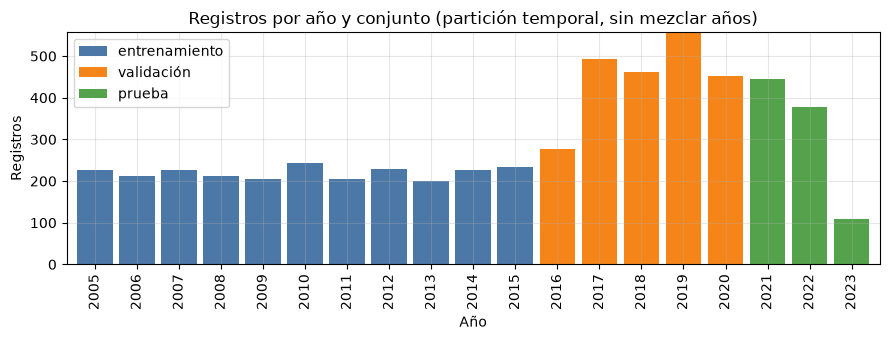

In [19]:
# PASO 1. Filtrar la base de modelado
panel = integ[
    integ["tiene_temperatura"]
    & integ["tiene_rendimiento"]
    & (integ["rendimiento_t_ha"] > 0)
].copy()

# PASO 2. Partición temporal (por año, sin mezclar años)
panel["split"] = np.select(
    [panel["anio"] <= ANIO_TRAIN_MAX, panel["anio"] <= ANIO_VAL_MAX],
    ["entrenamiento", "validación"],
    default="prueba",
)
ORDEN_SPLIT = ["entrenamiento", "validación", "prueba"]

# Registrar cuántas filas había antes y después del filtro (para trazabilidad)
registrar("Base de modelado", len(integ), len(panel),
          "Solo registros con rendimiento > 0 y temperatura")

# PASO 3. Resumen de cada conjunto
resumen_split = (
    panel.groupby("split")
    .agg(
        registros=("anio", "size"),
        municipios=("id_municipio", "nunique"),
        cultivos=("id_cultivo", "nunique"),
        anio_min=("anio", "min"),
        anio_max=("anio", "max"),
    )
    .reindex(ORDEN_SPLIT)   # fuerza el orden: entrenamiento, validación, prueba
)
display(resumen_split)

# Control de calidad: ningún conjunto puede estar vacío ni tener 50 registros o menos
assert resumen_split["registros"].notna().all() and (resumen_split["registros"] > 50).all(), \
    "Algún conjunto quedó con muy pocos registros: ajusta ANIO_TRAIN_MAX / ANIO_VAL_MAX"

# PASO 4. Gráfico: registros por año, coloreados por conjunto
conteo_anio_split = pd.crosstab(panel["anio"], panel["split"])[ORDEN_SPLIT]

fig, ax = plt.subplots(figsize=(9, 3.5))
conteo_anio_split.plot.bar(
    stacked=True, ax=ax, width=0.85,
    color=["#4C78A8", "#F58518", "#54A24B"],   # azul=entren., naranja=valid., verde=prueba
)
ax.set_title("Registros por año y conjunto (partición temporal, sin mezclar años)")
ax.set_xlabel("Año")
ax.set_ylabel("Registros")
ax.legend(title=None)

plt.tight_layout()
plt.savefig(CARPETA_FIG / "particion_temporal.png", dpi=150)
plt.show()

---
# 3. Variables sin fuga de datos

## 3.1 Qué se calcula y con qué años

La función `construir_variables(df, anio_ref)` recibe el panel y un **año de referencia** (`ANIO_TRAIN_MAX`). Todo lo que sea "normal histórica" se calcula con los registros de años ≤ `anio_ref`:

- **Rendimiento relativo** `rend_rel` = rendimiento ÷ mediana del cultivo (solo entrenamiento).
- **Objetivo** `y` = `rend_rel` − promedio de `rend_rel` del municipio-cultivo-ciclo (solo entrenamiento). Mide cuánto rindió el cultivo ese año **frente a lo normal en ese municipio**; así el modelo no aprende "este municipio rinde más" sino "este año rindió más o menos de lo habitual".
- **Temperatura normal** `t_hist` y `amp_hist`: promedio por municipio (solo entrenamiento); `clima_ord` = tercil (0 frío, 1 templado, 2 cálido).
- **Anomalías** `t_anom`, `amp_anom` = valor del año − normal; `t_anom_prev` = anomalía del año anterior.
- **Rezago del objetivo** `y_prev` = `y` del año anterior del mismo municipio-cultivo-ciclo (información pasada, disponible al predecir).

Como `y` ya descuenta la normal de cada municipio-cultivo, el modelo no necesita efectos fijos por municipio ni por cultivo.

In [20]:
def construir_variables(df, anio_ref):
    # Devuelve (tabla de modelado, tabla de temperatura municipio-año). Referencias SOLO con años <= anio_ref.
    d = df.copy()

    # 1) Rendimiento relativo: mediana del cultivo con entrenamiento
    med = (d[d["anio"] <= anio_ref].groupby("id_cultivo")["rendimiento_t_ha"].median().rename("mediana_ref"))
    d = d.merge(med, on="id_cultivo", how="left", validate="many_to_one")
    d["rend_rel"] = d["rendimiento_t_ha"] / d["mediana_ref"]

    # 2) Objetivo: rend_rel menos la normal del municipio-cultivo-ciclo (entrenamiento)
    ref = (d[d["anio"] <= anio_ref].groupby(["id_municipio", "id_cultivo", "ciclo"])["rend_rel"]
           .agg(rend_hist="mean", n_ref="count").reset_index())
    d = d.merge(ref, on=["id_municipio", "id_cultivo", "ciclo"], how="left", validate="many_to_one")
    d["y"] = (d["rend_rel"] - d["rend_hist"]).where(d["n_ref"] >= MIN_ANIOS_REND)

    # 3) Temperatura: una fila por municipio-año; normal con entrenamiento
    temp = (df[df["tiene_temperatura"]].drop_duplicates(["id_municipio", "anio"])
            [["id_municipio", "anio", "t_media", "amplitud_termica"]].copy())
    hist = (temp[temp["anio"] <= anio_ref].groupby("id_municipio")
            .agg(t_hist=("t_media", "mean"), amp_hist=("amplitud_termica", "mean"), n_t=("anio", "nunique"))
            .reset_index())
    hist = hist[hist["n_t"] >= MIN_ANIOS_TEMP].copy()
    hist["clima_ord"] = pd.qcut(hist["t_hist"].rank(method="first"), 3, labels=[0, 1, 2]).astype(int)
    temp = temp.merge(hist, on="id_municipio", how="inner", validate="many_to_one")
    temp["t_anom"] = temp["t_media"] - temp["t_hist"]
    temp["amp_anom"] = temp["amplitud_termica"] - temp["amp_hist"]
    prev = (temp[["id_municipio", "anio", "t_anom"]].assign(anio=lambda t: t["anio"] + 1)
            .rename(columns={"t_anom": "t_anom_prev"}))
    temp = temp.merge(prev, on=["id_municipio", "anio"], how="left", validate="one_to_one")
    d = d.merge(temp[["id_municipio", "anio", "t_hist", "clima_ord", "t_anom", "amp_anom", "t_anom_prev"]],
                on=["id_municipio", "anio"], how="left", validate="many_to_one")

    # 4) Rezago del objetivo y controles
    yprev = (d[["id_municipio", "id_cultivo", "ciclo", "anio", "y"]].assign(anio=lambda t: t["anio"] + 1)
             .rename(columns={"y": "y_prev"}))
    d = d.merge(yprev, on=["id_municipio", "id_cultivo", "ciclo", "anio"], how="left", validate="one_to_one")
    d["es_perm"] = (d["grupo"] == "Permanente").astype(int)
    d["log_ha"] = np.log1p(d["hectareas_sembradas"])
    d["clima_ord"] = d["clima_ord"]
    return d.sort_values(LLAVE_CULTIVO).reset_index(drop=True), temp

vars_df, temp_ref = construir_variables(panel[LLAVE_CULTIVO + ["municipio", "subregion", "grupo", "cultivo", "split",
                                                               "rendimiento_t_ha", "hectareas_sembradas",
                                                               "tiene_temperatura", "t_media", "amplitud_termica"]],
                                        ANIO_TRAIN_MAX)

## 3.2 ¿Cuántos registros se pierden y por qué?

Un registro entra al modelo solo si tiene **objetivo** (su municipio-cultivo-ciclo tiene al menos `MIN_ANIOS_REND` años en entrenamiento) y **temperatura de referencia** (su municipio tiene al menos `MIN_ANIOS_TEMP` años de temperatura en entrenamiento). Esto deja fuera, sobre todo en prueba, municipios cuya estación empezó a operar tarde: sin historia previa no se puede saber qué es "normal" para ellos.

In [21]:
d = vars_df
d["tiene_y"] = d["y"].notna()
d["tiene_clima"] = d["t_anom"].notna() & d["amp_anom"].notna()
d["en_modelo"] = d["tiene_y"] & d["tiene_clima"]

perdidas = (d.groupby("split").agg(registros_panel=("anio", "size"), con_objetivo=("tiene_y", "sum"),
                                   con_clima=("tiene_clima", "sum"), en_modelo=("en_modelo", "sum"))
            .reindex(ORDEN_SPLIT))
perdidas["% que entra"] = (perdidas["en_modelo"] / perdidas["registros_panel"] * 100).round(1)
display(perdidas)

modelo_df = d[d["en_modelo"]].copy()
registrar("Variables sin fuga", len(d), len(modelo_df),
          "Se excluyen registros sin normal de rendimiento o de temperatura en entrenamiento")
assert (modelo_df["split"].value_counts().reindex(ORDEN_SPLIT) > 30).all(), "Un conjunto quedó casi vacío tras exigir historia en entrenamiento"

,registros_panel,con_objetivo,con_clima,en_modelo,% que entra
split,,,,,
entrenamiento,2421,2184,2376,2184,90.2
validación,2240,701,1023,701,31.3
prueba,932,310,449,310,33.3


## 3.3 Prueba anti-fuga

Dos comprobaciones automáticas:

1. **Por construcción:** en entrenamiento, el objetivo promedia 0 por municipio-cultivo-ciclo y la anomalía térmica promedia 0 por municipio.
2. **Perturbación:** se **destruye** el periodo de prueba (rendimientos ×10 y temperaturas +5 °C), se reconstruyen las variables y se verifica que **ninguna** variable de entrenamiento ni de validación cambió. Si cambiara, habría fuga.

In [22]:
tr = modelo_df[modelo_df["split"] == "entrenamiento"]
max_y = tr.groupby(["id_municipio", "id_cultivo", "ciclo"])["y"].mean().abs().max()
t_tr = temp_ref[temp_ref["anio"] <= ANIO_TRAIN_MAX]
max_t = t_tr.groupby("id_municipio")["t_anom"].mean().abs().max()

base_cols = LLAVE_CULTIVO + ["municipio", "subregion", "grupo", "cultivo", "split", "rendimiento_t_ha",
                             "hectareas_sembradas", "tiene_temperatura", "t_media", "amplitud_termica"]
pert = panel[base_cols].copy()
en_prueba = pert["anio"] > ANIO_VAL_MAX
pert.loc[en_prueba, "rendimiento_t_ha"] *= 10
pert.loc[en_prueba, "t_media"] += 5
pert.loc[en_prueba, "amplitud_termica"] += 3
d_pert, _ = construir_variables(pert, ANIO_TRAIN_MAX)

cols_cmp = ["y", "rend_rel", "t_anom", "amp_anom", "t_anom_prev", "t_hist", "clima_ord", "y_prev"]
a = vars_df[vars_df["anio"] <= ANIO_VAL_MAX][LLAVE_CULTIVO + cols_cmp].reset_index(drop=True)
b = d_pert[d_pert["anio"] <= ANIO_VAL_MAX][LLAVE_CULTIVO + cols_cmp].reset_index(drop=True)
assert a[LLAVE_CULTIVO].equals(b[LLAVE_CULTIVO])
diferencias = {c: int((~np.isclose(a[c], b[c], equal_nan=True)).sum()) for c in cols_cmp}

hay_fuga = max_y >= 1e-9 or max_t >= 1e-9 or sum(diferencias.values()) > 0

descripcion = {
    "y": "Anomalía del rendimiento: rendimiento menos su promedio de entrenamiento (por municipio, cultivo y ciclo)",
    "rend_rel": "Rendimiento relativo: rendimiento dividido por su promedio de referencia",
    "t_anom": "Anomalía de temperatura: temperatura media del año menos la media de entrenamiento del municipio",
    "amp_anom": "Anomalía de amplitud térmica: amplitud del año menos la amplitud promedio de entrenamiento",
    "t_anom_prev": "Anomalía de temperatura del año anterior",
    "t_hist": "Temperatura media histórica del municipio (solo con años de entrenamiento)",
    "clima_ord": "Clima del municipio codificado como categoría ordenada (de más frío a más cálido)",
    "y_prev": "Anomalía del rendimiento (y) del año anterior",
}

tabla = pd.DataFrame({
    "Variable": cols_cmp,
    "Qué es": [descripcion[c] for c in cols_cmp],
    "Valores que cambiaron": [diferencias[c] for c in cols_cmp],
})
display(tabla.style.hide(axis="index").set_properties(subset=["Qué es"], **{"text-align": "left"}))

if hay_fuga:
    display(HTML("<h3 style='color:#c00'>HAY FUGA de información</h3>"))
else:
    display(HTML("<h3 style='color:#2a7a2a'>NO HAY FUGA de información</h3>"))

Variable,Qué es,Valores que cambiaron
y,"Anomalía del rendimiento: rendimiento menos su promedio de entrenamiento (por municipio, cultivo y ciclo)",0
rend_rel,Rendimiento relativo: rendimiento dividido por su promedio de referencia,0
t_anom,Anomalía de temperatura: temperatura media del año menos la media de entrenamiento del municipio,0
amp_anom,Anomalía de amplitud térmica: amplitud del año menos la amplitud promedio de entrenamiento,0
t_anom_prev,Anomalía de temperatura del año anterior,0
t_hist,Temperatura media histórica del municipio (solo con años de entrenamiento),0
clima_ord,Clima del municipio codificado como categoría ordenada (de más frío a más cálido),0
y_prev,Anomalía del rendimiento (y) del año anterior,0


---
# 4. Líneas base

Un modelo solo vale algo si **supera a lo simple**. Se definen dos referencias que no aprenden nada de la temperatura:

- **B0, promedio:** predice siempre el promedio del objetivo en entrenamiento. Como `y` es una anomalía, es casi 0 ("este año rinde lo normal").
- **B1, persistencia:** predice que el año rinde igual que el anterior (`y_prev`). Si no hay dato del año anterior, usa B0.

La tercera referencia (B2, el mismo algoritmo **sin** variables de la integración) se construye en la sección 5.

In [23]:
def metricas(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "MSE": mean_squared_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": r2_score(y, p)}

def partes(nombre):
    return modelo_df[modelo_df["split"] == nombre]

# Variables dummy del clima (Cap. 9): N-1 categorías; la referencia es el clima frío
_clima = pd.Categorical(modelo_df["clima_ord"].map({0: "frio", 1: "templado", 2: "calido"}),
                        categories=["frio", "templado", "calido"])
modelo_df[["clima_templado", "clima_calido"]] = pd.get_dummies(_clima, drop_first=True).astype(int).to_numpy()

tr_df, va_df, te_df = partes("entrenamiento"), partes("validación"), partes("prueba")
trva_df = pd.concat([tr_df, va_df])
y_tr, y_va, y_te = tr_df["y"], va_df["y"], te_df["y"]

media_tr = y_tr.mean()
pred_b0_va = np.full(len(va_df), media_tr)
pred_b0_te = np.full(len(te_df), trva_df["y"].mean())
pred_b1_va = va_df["y_prev"].fillna(media_tr).to_numpy()
pred_b1_te = te_df["y_prev"].fillna(trva_df["y"].mean()).to_numpy()

RES = {}      # nombre -> dict con predicciones, métricas y modelo
RES["B0 · Promedio del entrenamiento"] = {"tipo": "Línea base", "features": [], "val": metricas(y_va, pred_b0_va),
                                          "test": metricas(y_te, pred_b0_te), "pred": pred_b0_te}
RES["B1 · Persistencia (año anterior)"] = {"tipo": "Línea base", "features": ["y_prev"], "val": metricas(y_va, pred_b1_va),
                                           "test": metricas(y_te, pred_b1_te), "pred": pred_b1_te}
print(f"Cobertura del año anterior en prueba: {te_df['y_prev'].notna().mean():.1%} de los registros")
pd.DataFrame({k: v["test"] for k, v in RES.items()}).T.round(4)

Cobertura del año anterior en prueba: 68.7% de los registros


,MAE,MSE,RMSE,R2
B0 · Promedio del entrenamiento,0.4625,0.3998,0.6323,-0.002
B1 · Persistencia (año anterior),0.3210,0.3292,0.5737,0.175


---
# 5. Modelos

## 5.1 Elección del algoritmo (justificación)

| Criterio | `HistGradientBoostingRegressor` | `Ridge` |
|---|---|---|
| Relaciones no lineales e interacciones (p. ej. cultivo × temperatura) | Las captura sin especificarlas | Solo lineales |
| Faltantes (`t_anom_prev`, `y_prev`) | Los maneja de forma nativa | Requiere imputar |
| Pocos datos (miles de filas, cola larga) | Funciona bien con regularización | Estable y difícil de sobreajustar |
| Interpretación | Permutación y SHAP | Coeficientes directos |

Por eso se ajustan **los dos**: el *gradient boosting* es el modelo principal y *Ridge* sirve de contraste interpretable. La pérdida es el error cuadrático, y se evalúa con MAE porque el rendimiento tiene cola derecha larga (asimetría de 3,5 en la Parte 2).

## 5.2 Ajuste

Para cada conjunto de variables y algoritmo: se prueban los hiperparámetros del grid **entrenando con entrenamiento y midiendo MAE en validación**; se elige el mejor y se **reentrena con entrenamiento + validación** para evaluar en prueba. Todos los modelos reciben la **misma** cantidad de esfuerzo de búsqueda, para que la comparación sea justa.

In [24]:
def hacer_modelo(algoritmo, p):
    if algoritmo == "hgb":
        return HistGradientBoostingRegressor(loss="absolute_error", max_iter=250, random_state=SEMILLA, **p)
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge(**p))

def ajustar(nombre, tipo, algoritmo, features):
    grid = GRID_HGB if algoritmo == "hgb" else GRID_RIDGE
    busqueda = []
    for p in grid:
        m = hacer_modelo(algoritmo, p).fit(tr_df[features], y_tr)
        busqueda.append((mean_absolute_error(y_va, m.predict(va_df[features])), p))
    mae_val, mejor = min(busqueda, key=lambda t: t[0])
    # métricas de validación con el modelo entrenado solo con entrenamiento
    m_val = hacer_modelo(algoritmo, mejor).fit(tr_df[features], y_tr)
    # reentrenar con entrenamiento + validación para la prueba
    final = hacer_modelo(algoritmo, mejor).fit(trva_df[features], trva_df["y"])
    pred = final.predict(te_df[features])
    RES[nombre] = {"tipo": tipo, "features": features, "params": mejor, "algoritmo": algoritmo,
                   "val": metricas(y_va, m_val.predict(va_df[features])), "test": metricas(y_te, pred),
                   "pred": pred, "modelo": final}
    return mejor

ESPECIFICACIONES = [
    ("B2 · Boosting sin integración (F_BASE)",   "Línea base", "hgb",   F_BASE),
    ("M1 · Boosting + clima normal (F_NIVEL)",   "Modelo",     "hgb",   F_NIVEL),
    ("M2 · Boosting + clima completo (F_COMPLETO)", "Modelo",  "hgb",   F_COMPLETO),
    ("M3 · Ridge + clima normal (F_NIVEL)",      "Modelo",     "ridge", F_NIVEL),
    ("M4 · Ridge + clima completo (F_COMPLETO)", "Modelo",     "ridge", F_COMPLETO),
]
for nombre, tipo, alg, feats in ESPECIFICACIONES:
    mejor = ajustar(nombre, tipo, alg, feats)

## 5.3 Multicolinealidad y variables dummy (Cap. 9)

Los modelos lineales son sensibles a variables muy correlacionadas entre sí (multicolinealidad): los coeficientes se vuelven inestables y cambian de signo. Los árboles (*boosting*) no tienen ese problema, por eso esta sección solo aplica a los modelos lineales.

- **Dummies:** `clima_ord` (0, 1, 2) se reemplaza por `clima_templado` y `clima_calido` (N-1 dummies; la referencia es el clima frío), como `pd.get_dummies(drop_first=True)` del libro.
- **Diagnóstico:** matriz de correlación y **VIF** (factor de inflación de la varianza; > 10 se considera problemático), calculados **solo con entrenamiento**.
- **Remedio:** se elimina de a una la variable con mayor VIF mientras supere el umbral, **protegiendo las tres anomalías** (`t_anom`, `t_anom_prev`, `amp_anom`) porque son las variables de la hipótesis.

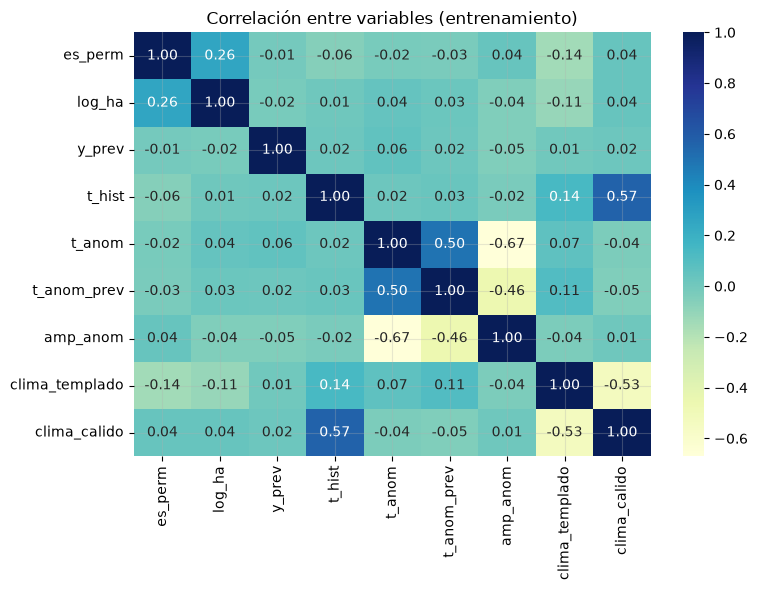

,VIF inicial,VIF final,Se conserva
variable,,,
es_perm,1.09,1.09,True
log_ha,1.09,1.09,True
y_prev,1.00,1.00,True
t_hist,2.48,2.48,True
t_anom,1.99,1.99,True
t_anom_prev,1.39,1.39,True
amp_anom,1.89,1.89,True
clima_templado,2.40,2.40,True
clima_calido,3.37,3.37,True


In [25]:
ANOMALIAS = ["t_anom", "t_anom_prev", "amp_anom"]
F_LINEAL_INICIAL = [f for f in F_COMPLETO if f != "clima_ord"] + ["clima_templado", "clima_calido"]
X_vif = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(tr_df[F_LINEAL_INICIAL]),
                     columns=F_LINEAL_INICIAL, index=tr_df.index)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(X_vif.corr(), annot=True, fmt=".2f", cmap="YlGnBu", ax=ax)
ax.set_title("Correlación entre variables (entrenamiento)")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "correlacion_variables.png", dpi=150); plt.show()

def calcular_vif(X):
    Xc = sm.add_constant(X, has_constant="add")
    return pd.Series([variance_inflation_factor(Xc.to_numpy(), i) for i in range(1, Xc.shape[1])], index=X.columns)

F_LINEAL = list(F_LINEAL_INICIAL)
vif_ini = calcular_vif(X_vif[F_LINEAL])
eliminadas = []
while True:
    v_ = calcular_vif(X_vif[F_LINEAL])
    cand_ = v_.drop(ANOMALIAS, errors="ignore")
    if len(cand_) <= 1 or not (cand_.max() > UMBRAL_VIF):
        break
    quitar = cand_.idxmax()
    F_LINEAL.remove(quitar)
    eliminadas.append((quitar, round(float(cand_.max()), 1)))
vif_fin = calcular_vif(X_vif[F_LINEAL])

vif_tab = pd.DataFrame({"VIF inicial": vif_ini, "VIF final": vif_fin}).round(2)
vif_tab["Se conserva"] = vif_tab["VIF final"].notna()
vif_tab.index.name = "variable"
display(vif_tab.style.format({"VIF inicial": "{:.2f}", "VIF final": "{:.2f}"}, na_rep="eliminada")
        .set_caption(f"VIF en entrenamiento (umbral = {UMBRAL_VIF})"))

## 5.4 Regresión lineal múltiple y polinomial (Cap. 9)

Se ajustan dos modelos del capítulo 9 sobre `F_LINEAL` (mismas reglas que el resto: hiperparámetros en validación y reentrenamiento con entrenamiento + validación):

- **M5, regresión lineal múltiple (OLS):** la ecuación `y = β0 + β1·x1 + … + ε` estimada con mínimos cuadrados. Es el contraste directo con H1 (signo de `t_anom`).
- **M6, regresión polinomial:** agrega potencias e interacciones (`PolynomialFeatures`); el grado se elige en validación entre `GRADOS_POLI`.

Las métricas son las del libro: **R², MSE, MAE y RMSE**, todas en prueba.

In [26]:
def ajustar_lineal(nombre, estimador, features):
    m_val = clone(estimador).fit(tr_df[features], y_tr)
    final_ = clone(estimador).fit(trva_df[features], trva_df["y"])
    pred_ = final_.predict(te_df[features])
    RES[nombre] = {"tipo": "Modelo", "features": features, "params": {}, "algoritmo": "lineal",
                   "val": metricas(y_va, m_val.predict(va_df[features])), "test": metricas(y_te, pred_),
                   "pred": pred_, "modelo": final_}
    return final_

# M5: regresión lineal múltiple
NOMBRE_OLS = "M5 · Regresión lineal múltiple (F_LINEAL)"
ols_pipe = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LinearRegression())
ols_final = ajustar_lineal(NOMBRE_OLS, ols_pipe, F_LINEAL)

# M6: regresión polinomial (grado elegido en validación)
def pipe_poli(g):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         PolynomialFeatures(g, include_bias=False), LinearRegression())
mae_por_grado = {g_: mean_absolute_error(y_va, pipe_poli(g_).fit(tr_df[F_LINEAL], y_tr).predict(va_df[F_LINEAL]))
                 for g_ in GRADOS_POLI}
GRADO_OPT = min(mae_por_grado, key=mae_por_grado.get)
NOMBRE_POLI = f"M6 · Regresión polinomial grado {GRADO_OPT} (F_LINEAL)"
ajustar_lineal(NOMBRE_POLI, pipe_poli(GRADO_OPT), F_LINEAL)
print("MAE de validación por grado:", {k: round(v, 5) for k, v in mae_por_grado.items()}, "→ grado elegido:", GRADO_OPT)

# Comparación con el boosting (prueba)
comp_lin = pd.DataFrame({k: RES[k]["test"] for k in ["B2 · Boosting sin integración (F_BASE)",
                                                    "M2 · Boosting + clima completo (F_COMPLETO)",
                                                    NOMBRE_OLS, NOMBRE_POLI]}).T
display(comp_lin[["MAE", "MSE", "RMSE", "R2"]].style.format("{:.5f}").set_caption("Métricas del capítulo 9 en prueba"))

# Coeficientes estandarizados de la regresión lineal (signo y magnitud)
try:
    nombres_coef = list(ols_final[:-1].get_feature_names_out(F_LINEAL))
except Exception:
    nombres_coef = [f"x{i}" for i in range(len(ols_final[-1].coef_))]
coefs = pd.Series(ols_final[-1].coef_, index=nombres_coef, name="coeficiente estandarizado")
coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
display(coefs.to_frame().style.format("{:+.5f}").set_caption("Regresión lineal: coeficientes (variables estandarizadas)"))
if "t_anom" in coefs.index:
    signo = "negativo (consistente con H1)" if coefs["t_anom"] < 0 else "positivo (contrario a H1)"
    print(f"Signo del coeficiente de t_anom en la regresión lineal: {signo}. "
          "La significancia estadística se contrasta en la sección 9 con errores agrupados.")

MAE de validación por grado: {2: 0.35333, 3: 2.20586} → grado elegido: 2


,MAE,MSE,RMSE,R2
B2 · Boosting sin integración (F_BASE),0.33341,0.30725,0.55431,0.22993
M2 · Boosting + clima completo (F_COMPLETO),0.35832,0.31919,0.56497,0.20002
M5 · Regresión lineal múltiple (F_LINEAL),0.35561,0.30860,0.55552,0.22654
M6 · Regresión polinomial grado 2 (F_LINEAL),0.35890,0.30214,0.54967,0.24276


,coeficiente estandarizado
y_prev,+0.26091
missingindicator_y_prev,+0.02789
missingindicator_t_anom_prev,-0.02764
t_anom,-0.01310
t_hist,-0.00880
clima_templado,+0.00817
es_perm,+0.00630
log_ha,-0.00428
clima_calido,-0.00243
t_anom_prev,-0.00066


Signo del coeficiente de t_anom en la regresión lineal: negativo (consistente con H1). La significancia estadística se contrasta en la sección 9 con errores agrupados.


---
# 6. Resultados en el conjunto de prueba

Se reportan MAE, RMSE y R² **fuera de muestra** y la **mejora relativa del MAE frente a B0** (`1 − MAE/MAE_B0`; positiva = mejor que predecir el promedio). Un R² cercano a 0 o negativo indica que el modelo casi no explica la variación del objetivo.

,Tipo,N variables,MAE validación,MAE prueba,MSE prueba,RMSE prueba,R² prueba,Mejora vs B0 (MAE)
Modelo,,,,,,,,
B0 · Promedio del entrenamiento,Línea base,0,0.3979,0.4625,0.3998,0.6323,-0.0020,+0.00%
B1 · Persistencia (año anterior),Línea base,1,0.2258,0.3210,0.3292,0.5737,0.1750,+30.58%
B2 · Boosting sin integración (F_BASE),Línea base,3,0.2851,0.3334,0.3073,0.5543,0.2299,+27.90%
M1 · Boosting + clima normal (F_NIVEL),Modelo,5,0.2895,0.3368,0.3076,0.5546,0.2292,+27.17%
M2 · Boosting + clima completo (F_COMPLETO),Modelo,8,0.2932,0.3583,0.3192,0.5650,0.2000,+22.52%
M3 · Ridge + clima normal (F_NIVEL),Modelo,5,0.3059,0.3524,0.3038,0.5512,0.2385,+23.80%
M4 · Ridge + clima completo (F_COMPLETO),Modelo,8,0.3071,0.3559,0.3092,0.5561,0.2250,+23.04%
M5 · Regresión lineal múltiple (F_LINEAL),Modelo,9,0.3071,0.3556,0.3086,0.5555,0.2265,+23.10%
M6 · Regresión polinomial grado 2 (F_LINEAL),Modelo,9,0.3533,0.3589,0.3021,0.5497,0.2428,+22.39%


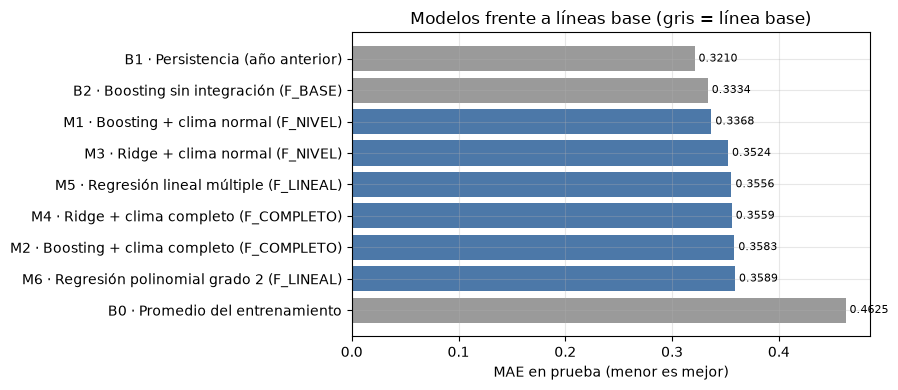

In [27]:
mae_b0 = RES["B0 · Promedio del entrenamiento"]["test"]["MAE"]
tabla = pd.DataFrame([{"Modelo": k, "Tipo": v["tipo"], "N variables": len(v["features"]),
                       "MAE validación": v["val"]["MAE"], "MAE prueba": v["test"]["MAE"],
                       "MSE prueba": v["test"]["MSE"], "RMSE prueba": v["test"]["RMSE"], "R² prueba": v["test"]["R2"],
                       "Mejora vs B0 (MAE)": 1 - v["test"]["MAE"] / mae_b0} for k, v in RES.items()])
tabla = tabla.set_index("Modelo")
display(tabla.style.format({"MAE validación": "{:.4f}", "MAE prueba": "{:.4f}", "MSE prueba": "{:.4f}", "RMSE prueba": "{:.4f}",
                            "R² prueba": "{:.4f}", "Mejora vs B0 (MAE)": "{:+.2%}"})
        .background_gradient(subset=["MAE prueba"], cmap="Greens_r")
        .set_caption(f"Prueba: {len(te_df):,} registros, años {te_df['anio'].min()}-{te_df['anio'].max()}"))

fig, ax = plt.subplots(figsize=(9, 4))
orden = tabla["MAE prueba"].sort_values()
colores = ["#9A9A9A" if tabla.loc[i, "Tipo"] == "Línea base" else "#4C78A8" for i in orden.index]
ax.barh(orden.index, orden.values, color=colores)
ax.invert_yaxis(); ax.set_xlabel("MAE en prueba (menor es mejor)")
ax.set_title("Modelos frente a líneas base (gris = línea base)")
for i, v in enumerate(orden.values):
    ax.text(v, i, f" {v:.4f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(CARPETA_FIG / "comparacion_modelos.png", dpi=150); plt.show()

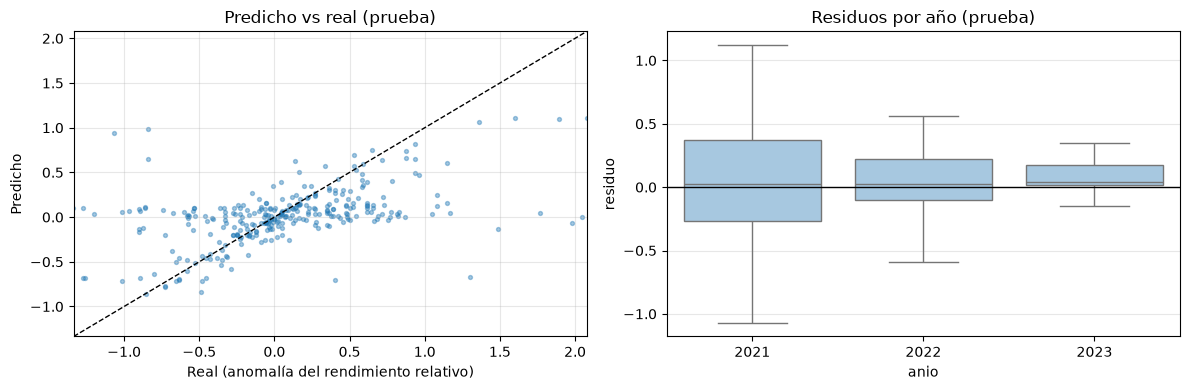

In [28]:
# Predicho vs real y residuos por año (modelo con clima completo)
mejor_nombre = "M2 · Boosting + clima completo (F_COMPLETO)"
pred_m2 = RES[mejor_nombre]["pred"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(y_te, pred_m2, s=8, alpha=0.4)
lim = np.nanpercentile(np.r_[y_te, pred_m2], [0.5, 99.5])
axs[0].plot(lim, lim, "k--", lw=1)
axs[0].set_xlim(lim); axs[0].set_ylim(lim)
axs[0].set_xlabel("Real (anomalía del rendimiento relativo)"); axs[0].set_ylabel("Predicho")
axs[0].set_title("Predicho vs real (prueba)")
res_df = pd.DataFrame({"anio": te_df["anio"].to_numpy(), "residuo": y_te.to_numpy() - pred_m2})
sns.boxplot(data=res_df, x="anio", y="residuo", ax=axs[1], color="#9ECAE9", showfliers=False)
axs[1].axhline(0, color="k", lw=1); axs[1].set_title("Residuos por año (prueba)")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "predicho_vs_real.png", dpi=150); plt.show()

---
# 7. ¿Aporta realmente la temperatura?

Ver que `M2` tiene un MAE un poco menor que `B2` **no basta**: con miles de registros una diferencia pequeña puede ser ruido. Se mide la **diferencia de error absoluto registro a registro** (positiva = el modelo con más información acierta más) y se calcula un intervalo de confianza del 95 % con **bootstrap por conglomerados** (municipio-año): los cultivos de un mismo municipio y año comparten la misma temperatura, así que no son observaciones independientes.

Tres comparaciones, de menor a mayor aislamiento de la hipótesis:

| Comparación | Pregunta |
|---|---|
| M1 vs B2 | ¿Ayuda saber el clima **normal** del municipio? |
| **M2 vs M1** | ¿Ayuda saber cómo fue el **año** respecto a lo normal? (**la hipótesis del estudio**) |
| M2 vs B2 | ¿Ayuda toda la información de la integración? |

,Δ MAE (ref − modelo),IC95 inferior,IC95 superior,Mejora significativa
Comparación,,,,
M1 vs B2 (clima normal),-0.00340,-0.01103,+0.00425,No
M2 vs M1 (anomalías del año),-0.02152,-0.04311,+0.00079,No
M2 vs B2 (toda la integración),-0.02492,-0.05244,+0.00291,No


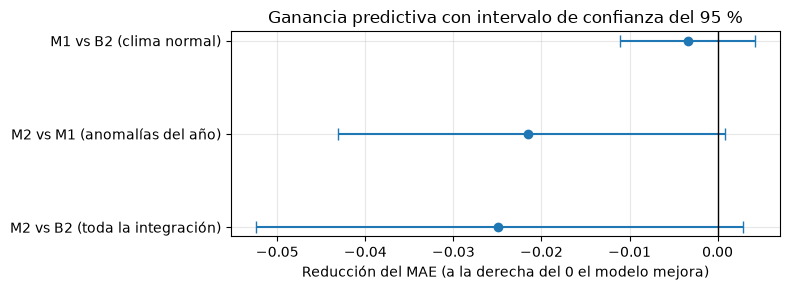

**Lectura.** Pasar de M1 a M2 (agregar las anomalías térmicas del año) cambia el MAE en **-0.02152** (positivo = mejora; IC95 %: -0.04311 a +0.00079). El intervalo incluye el 0: **con estos datos no se puede afirmar que las anomalías térmicas mejoren la predicción**. Esto no prueba que la temperatura no importe; indica que la señal del IDEAM (pocos municipios, una estación por municipio) no basta para detectarla.

In [29]:
def bootstrap_delta(y, p_ref, p_mod, clusters, n=N_BOOT, seed=SEMILLA):
    d = np.abs(y - p_ref) - np.abs(y - p_mod)                      # > 0: el modelo mejora
    g = pd.DataFrame({"c": clusters, "d": d}).groupby("c")["d"].agg(["sum", "count"])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), size=(n, len(g)))
    boots = g["sum"].to_numpy()[idx].sum(1) / g["count"].to_numpy()[idx].sum(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return d.mean(), lo, hi

cluster = (te_df["id_municipio"] + "_" + te_df["anio"].astype(str)).to_numpy()
y_arr = y_te.to_numpy()
B2, M1, M2 = (RES[k]["pred"] for k in ["B2 · Boosting sin integración (F_BASE)",
                                       "M1 · Boosting + clima normal (F_NIVEL)",
                                       "M2 · Boosting + clima completo (F_COMPLETO)"])
filas = []
for etiqueta, ref, mod in [("M1 vs B2 (clima normal)", B2, M1),
                           ("M2 vs M1 (anomalías del año)", M1, M2),
                           ("M2 vs B2 (toda la integración)", B2, M2)]:
    delta, lo, hi = bootstrap_delta(y_arr, ref, mod, cluster)
    filas.append({"Comparación": etiqueta, "Δ MAE (ref − modelo)": delta, "IC95 inferior": lo, "IC95 superior": hi,
                  "Mejora significativa": "Sí" if lo > 0 else "No"})
boot_tab = pd.DataFrame(filas).set_index("Comparación")
display(boot_tab.style.format({"Δ MAE (ref − modelo)": "{:+.5f}", "IC95 inferior": "{:+.5f}", "IC95 superior": "{:+.5f}"})
        .set_caption(f"Bootstrap por municipio-año ({N_BOOT} remuestreos, {len(set(cluster))} conglomerados)"))

fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(boot_tab["Δ MAE (ref − modelo)"], range(len(boot_tab)),
            xerr=[boot_tab["Δ MAE (ref − modelo)"] - boot_tab["IC95 inferior"],
                  boot_tab["IC95 superior"] - boot_tab["Δ MAE (ref − modelo)"]], fmt="o", capsize=4)
ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(boot_tab))); ax.set_yticklabels(boot_tab.index)
ax.set_xlabel("Reducción del MAE (a la derecha del 0 el modelo mejora)"); ax.invert_yaxis()
ax.set_title("Ganancia predictiva con intervalo de confianza del 95 %")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "bootstrap_ganancia.png", dpi=150); plt.show()

dif_hip = boot_tab.loc["M2 vs M1 (anomalías del año)"]
if dif_hip["IC95 inferior"] > 0:
    veredicto = ("El intervalo queda por encima de 0: la mejora es distinguible del ruido, aunque debe leerse junto con su tamaño "
                 "(¿qué fracción del error del modelo base representa?).")
elif dif_hip["IC95 superior"] < 0:
    veredicto = ("El intervalo queda por debajo de 0: **el modelo con anomalías predice peor que el modelo sin ellas** en prueba "
                 "(sobreajuste o ruido). Con estos datos las anomalías no ayudan a predecir.")
else:
    veredicto = ("El intervalo incluye el 0: **con estos datos no se puede afirmar que las anomalías térmicas mejoren la predicción**. "
                 "Esto no prueba que la temperatura no importe; indica que la señal del IDEAM (pocos municipios, una estación por "
                 "municipio) no basta para detectarla.")
display(Markdown(
    f"**Lectura.** Pasar de M1 a M2 (agregar las anomalías térmicas del año) cambia el MAE en **{dif_hip['Δ MAE (ref − modelo)']:+.5f}** "
    f"(positivo = mejora; IC95 %: {dif_hip['IC95 inferior']:+.5f} a {dif_hip['IC95 superior']:+.5f}). " + veredicto))

## 7.1 ¿Dónde acierta y dónde falla?

Un promedio global puede esconder que el modelo funciona en un grupo y no en otro. Se compara el MAE del modelo final (`M2`) con la línea base `B2` por grupo de cultivo, por clima del municipio y por año de prueba.

In [30]:
cmp = te_df[["anio", "grupo", "clima_ord", "id_municipio", "municipio", "cultivo", "y"]].copy()
cmp["err_B2"] = np.abs(cmp["y"] - B2)
cmp["err_M2"] = np.abs(cmp["y"] - M2)
cmp["clima"] = cmp["clima_ord"].map({0: "Frío", 1: "Templado", 2: "Cálido"})

def tabla_error(col):
    t = cmp.groupby(col).agg(registros=("y", "size"), MAE_B2=("err_B2", "mean"), MAE_M2=("err_M2", "mean"))
    t["Mejora de M2 sobre B2"] = 1 - t["MAE_M2"] / t["MAE_B2"]
    return t

for col in ["grupo", "clima", "anio"]:
    display(tabla_error(col).style.format({"MAE_B2": "{:.4f}", "MAE_M2": "{:.4f}", "Mejora de M2 sobre B2": "{:+.1%}"})
            .set_caption(f"Error por {col}"))

,registros,MAE_B2,MAE_M2,Mejora de M2 sobre B2
grupo,,,,
Permanente,196,0.2822,0.3054,-8.2%
Transitorio,114,0.4215,0.4493,-6.6%


,registros,MAE_B2,MAE_M2,Mejora de M2 sobre B2
clima,,,,
Cálido,99,0.2148,0.2388,-11.2%
Frío,92,0.3564,0.3456,+3.1%
Templado,119,0.4143,0.4676,-12.9%


,registros,MAE_B2,MAE_M2,Mejora de M2 sobre B2
anio,,,,
2021,147,0.4460,0.4427,+0.7%
2022,132,0.2520,0.3127,-24.1%
2023,31,0.1464,0.1529,-4.4%


## 7.2 Enfoque de clasificación (Cap. 10): ¿el año rindió por debajo de lo normal?

Se convierte el objetivo en una clase: **1 = el rendimiento estuvo por debajo de lo normal del municipio-cultivo** (`y < UMBRAL_CAIDA`) y **0 = normal o mejor**. Es la misma pregunta de la hipótesis, vista como clasificación, y permite usar las herramientas del capítulo 10.

- **Algoritmos del libro:** regresión logística, *Naive Bayes*, árbol de decisión, KNN y SVM.
- **Partición:** la misma partición temporal (el libro usa *holdout* aleatorio; aquí se evita mezclar años). Los hiperparámetros se eligen por **F1 en validación** y el modelo final se reentrena con entrenamiento + validación.
- **Dos conjuntos de variables:** `F_BASE` (sin integración) y `F_COMPLETO` (con la integración del IDEAM), para ver si la temperatura ayuda a clasificar.
- **Métricas:** matriz de confusión, accuracy, precision, recall, F1 y AUC-ROC, más una línea base (predecir siempre la clase mayoritaria).

Proporción de años 'bajo lo normal': entrenamiento 48.8% · validación 41.5% · prueba 48.1%


Algoritmo,Variables,F1 validación,Accuracy,Precision,Recall,F1,AUC
Regresión logística,Sin integración (F_BASE),0.719,0.735,0.853,0.544,0.664,0.835
Regresión logística,Con integración (F_COMPLETO),0.734,0.710,0.744,0.604,0.667,0.807
Naive Bayes,Sin integración (F_BASE),0.728,0.700,0.715,0.624,0.667,0.758
Naive Bayes,Con integración (F_COMPLETO),0.670,0.684,0.686,0.631,0.657,0.732
Árbol de decisión,Sin integración (F_BASE),0.760,0.745,0.850,0.570,0.683,0.803
Árbol de decisión,Con integración (F_COMPLETO),0.737,0.732,0.784,0.611,0.687,0.796
KNN,Sin integración (F_BASE),0.712,0.726,0.771,0.611,0.682,0.801
KNN,Con integración (F_COMPLETO),0.675,0.674,0.700,0.564,0.625,0.699
SVM,Sin integración (F_BASE),0.714,0.742,0.856,0.557,0.675,0.781
SVM,Con integración (F_COMPLETO),0.690,0.694,0.725,0.584,0.647,0.717


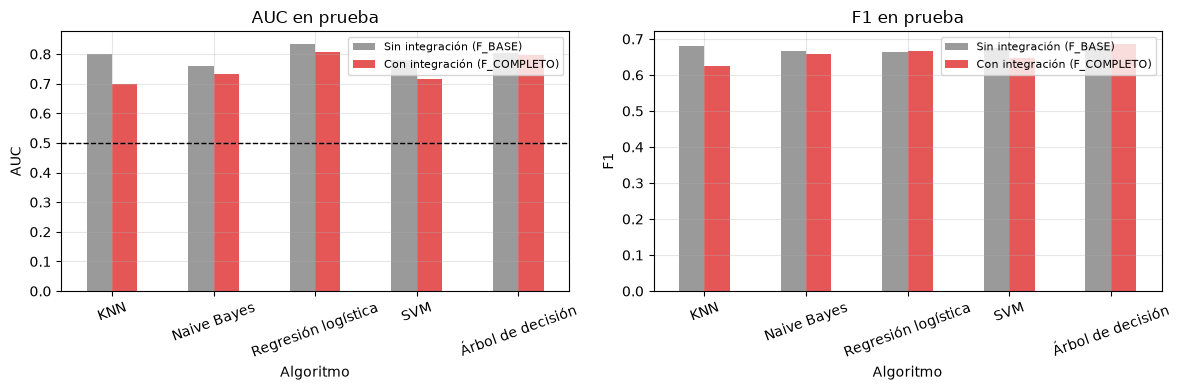

In [31]:
yc_tr = (y_tr < UMBRAL_CAIDA).astype(int).to_numpy()
yc_va = (y_va < UMBRAL_CAIDA).astype(int).to_numpy()
yc_te = (y_te < UMBRAL_CAIDA).astype(int).to_numpy()
yc_trva = (trva_df["y"] < UMBRAL_CAIDA).astype(int).to_numpy()
print(f"Proporción de años 'bajo lo normal': entrenamiento {yc_tr.mean():.1%} · validación {yc_va.mean():.1%} · prueba {yc_te.mean():.1%}")

ALG_CLF = {
    "Regresión logística": ("logreg", [{"C": c} for c in (0.1, 1, 10)]),
    "Naive Bayes": ("nb", [{"var_smoothing": v} for v in (1e-9, 1e-6, 1e-3)]),
    "Árbol de decisión": ("tree", [{"max_depth": d, "min_samples_leaf": l} for d in (3, 5, 8) for l in (20, 50)]),
    "KNN": ("knn", [{"n_neighbors": k} for k in (5, 15, 31)]),
    "SVM": ("svm", [{"C": c} for c in (0.5, 2.0)]),
}
CONJUNTOS_CLF = {"Sin integración (F_BASE)": F_BASE, "Con integración (F_COMPLETO)": F_COMPLETO}

def hacer_clf(alg, p):
    est = {"logreg": lambda: LogisticRegression(max_iter=1000, **p),
           "nb": lambda: GaussianNB(**p),
           "tree": lambda: DecisionTreeClassifier(random_state=SEMILLA, **p),
           "knn": lambda: KNeighborsClassifier(**p),
           "svm": lambda: SVC(kernel="rbf", random_state=SEMILLA, **p)}[alg]()
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), est)

def puntaje(modelo, X):
    return modelo.predict_proba(X)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X)

def metricas_clf(y, pred, score):
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, score)}

RES_CLF = {}
for alg_nombre, (alg, grid_) in ALG_CLF.items():
    for conj_nombre, feats in CONJUNTOS_CLF.items():
        mejor_f1, mejor_p = -1.0, None
        for p_ in grid_:
            m_ = hacer_clf(alg, p_).fit(tr_df[feats], yc_tr)
            f1_ = f1_score(yc_va, m_.predict(va_df[feats]), zero_division=0)
            if f1_ > mejor_f1:
                mejor_f1, mejor_p = f1_, p_
        final_clf = hacer_clf(alg, mejor_p).fit(trva_df[feats], yc_trva)
        pred_clf = final_clf.predict(te_df[feats])
        sc_clf = puntaje(final_clf, te_df[feats])
        RES_CLF[(alg_nombre, conj_nombre)] = {"params": mejor_p, "F1 validación": mejor_f1,
                                              "test": metricas_clf(yc_te, pred_clf, sc_clf),
                                              "pred": pred_clf, "score": sc_clf, "modelo": final_clf, "features": feats}

# Línea base: clase mayoritaria
base_clf = metricas_clf(yc_te, np.full(len(yc_te), int(yc_trva.mean() >= 0.5)), np.full(len(yc_te), 0.5))
filas_clf = [{"Algoritmo": a_, "Variables": c_, "F1 validación": r_["F1 validación"], **r_["test"]} for (a_, c_), r_ in RES_CLF.items()]
filas_clf.append({"Algoritmo": "Clase mayoritaria", "Variables": "—", "F1 validación": np.nan, **base_clf})
clf_tab = pd.DataFrame(filas_clf)
display(clf_tab.style.format({c_: "{:.3f}" for c_ in ["F1 validación", "Accuracy", "Precision", "Recall", "F1", "AUC"]}, na_rep="—")
        .background_gradient(subset=["AUC"], cmap="Greens").hide(axis="index")
        .set_caption(f"Clasificación en prueba ({len(yc_te):,} registros)"))

# Gráfico: AUC y F1 por algoritmo, con y sin integración
solo = clf_tab[clf_tab["Algoritmo"] != "Clase mayoritaria"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, met in zip(axs, ["AUC", "F1"]):
    solo.pivot(index="Algoritmo", columns="Variables", values=met)[list(CONJUNTOS_CLF)].plot.bar(ax=ax, color=["#9A9A9A", "#E45756"], rot=20)
    ax.set_ylabel(met); ax.set_title(f"{met} en prueba"); ax.legend(title=None, fontsize=8)
    if met == "AUC":
        ax.axhline(0.5, color="k", lw=1, ls="--")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "clasificacion_comparacion.png", dpi=150); plt.show()

Mejor clasificador (F1 en validación): Árbol de decisión {'max_depth': 5, 'min_samples_leaf': 20}


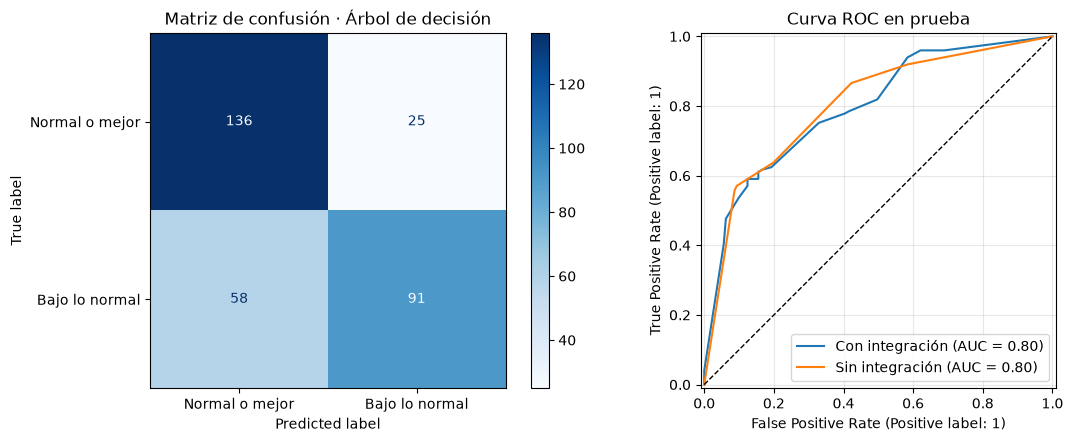

                precision    recall  f1-score   support

Normal o mejor       0.70      0.84      0.77       161
Bajo lo normal       0.78      0.61      0.69       149

      accuracy                           0.73       310
     macro avg       0.74      0.73      0.73       310
  weighted avg       0.74      0.73      0.73       310



**Lectura.** Con Árbol de decisión, agregar la integración cambia el AUC en **-0.0068** (IC95 %: -0.0508 a +0.0306): la diferencia de AUC no se distingue del ruido. Un AUC de 0,5 equivale a clasificar al azar; compárelo con la línea base de la tabla.

In [32]:
# Mejor clasificador con integración (elegido por F1 en validación, no en prueba)
cand_clf = {k: v for k, v in RES_CLF.items() if k[1].startswith("Con")}
clave_mejor = max(cand_clf, key=lambda k: cand_clf[k]["F1 validación"])
clave_ref = (clave_mejor[0], "Sin integración (F_BASE)")
mejor_clf_nombre = clave_mejor[0]
r_mejor, r_ref = RES_CLF[clave_mejor], RES_CLF[clave_ref]
print("Mejor clasificador (F1 en validación):", mejor_clf_nombre, r_mejor["params"])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_te, r_mejor["pred"], display_labels=["Normal o mejor", "Bajo lo normal"],
                                        values_format="d", cmap="Blues", ax=axs[0])
axs[0].grid(False); axs[0].set_title(f"Matriz de confusión · {mejor_clf_nombre}")
RocCurveDisplay.from_predictions(yc_te, r_mejor["score"], name="Con integración", ax=axs[1])
RocCurveDisplay.from_predictions(yc_te, r_ref["score"], name="Sin integración", ax=axs[1])
axs[1].plot([0, 1], [0, 1], "k--", lw=1); axs[1].set_title("Curva ROC en prueba")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "clasificacion_confusion_roc.png", dpi=150); plt.show()
print(classification_report(yc_te, r_mejor["pred"], target_names=["Normal o mejor", "Bajo lo normal"], zero_division=0))

# ¿La mejora de AUC por la integración es distinguible del ruido? (bootstrap por municipio-año)
cluster_te = (te_df["id_municipio"] + "_" + te_df["anio"].astype(str)).to_numpy()
def bootstrap_auc(y, s_ref, s_mod, grupos, n=N_BOOT_CLF, seed=SEMILLA):
    rng = np.random.default_rng(seed)
    por_grupo = [g.to_numpy() for _, g in pd.Series(np.arange(len(y))).groupby(grupos)]
    deltas = []
    for _ in range(n):
        sel = rng.integers(0, len(por_grupo), len(por_grupo))
        ii = np.concatenate([por_grupo[k] for k in sel])
        if len(np.unique(y[ii])) < 2:
            continue
        deltas.append(roc_auc_score(y[ii], s_mod[ii]) - roc_auc_score(y[ii], s_ref[ii]))
    lo_, hi_ = np.percentile(deltas, [2.5, 97.5])
    return {"delta": roc_auc_score(y, s_mod) - roc_auc_score(y, s_ref), "lo": lo_, "hi": hi_}

clf_delta = bootstrap_auc(yc_te, r_ref["score"], r_mejor["score"], cluster_te)
if clf_delta["lo"] > 0:
    veredicto_clf = "la integración mejora el AUC de forma distinguible del ruido"
elif clf_delta["hi"] < 0:
    veredicto_clf = "el modelo con integración clasifica peor que el que no la usa"
else:
    veredicto_clf = "la diferencia de AUC no se distingue del ruido"
display(Markdown(f"**Lectura.** Con {mejor_clf_nombre}, agregar la integración cambia el AUC en **{clf_delta['delta']:+.4f}** "
                 f"(IC95 %: {clf_delta['lo']:+.4f} a {clf_delta['hi']:+.4f}): {veredicto_clf}. "
                 f"Un AUC de 0,5 equivale a clasificar al azar; compárelo con la línea base de la tabla."))

## 7.3 Validación prospectiva año a año (Cap. 10: alternativa al k-fold)

El k-fold aleatorio del libro mezcla años y filtraría información futura. La versión correcta para series temporales es **entrenar con los años anteriores y probar en el año siguiente** (ventana creciente). Se aplica al mejor clasificador, con y sin integración, sobre los años de validación; el conjunto de prueba sigue sin tocarse.

In [33]:
alg_mejor = ALG_CLF[mejor_clf_nombre][0]
filas_cv = []
for anio_ in sorted(va_df["anio"].unique()):
    tr_cv, te_cv = trva_df[trva_df["anio"] < anio_], trva_df[trva_df["anio"] == anio_]
    ytr_cv, yte_cv = (tr_cv["y"] < UMBRAL_CAIDA).astype(int), (te_cv["y"] < UMBRAL_CAIDA).astype(int)
    if len(tr_cv) < 50 or ytr_cv.nunique() < 2 or yte_cv.nunique() < 2:
        continue
    for conj_nombre, feats in CONJUNTOS_CLF.items():
        m_ = hacer_clf(alg_mejor, RES_CLF[(mejor_clf_nombre, conj_nombre)]["params"]).fit(tr_cv[feats], ytr_cv)
        filas_cv.append({"Año probado": anio_, "Variables": conj_nombre,
                         "F1": f1_score(yte_cv, m_.predict(te_cv[feats]), zero_division=0),
                         "AUC": roc_auc_score(yte_cv, puntaje(m_, te_cv[feats]))})
if filas_cv:
    cv_tab = pd.DataFrame(filas_cv)
    display(cv_tab.pivot(index="Año probado", columns="Variables", values=["F1", "AUC"]).style.format("{:.3f}")
            .set_caption(f"Validación prospectiva · {mejor_clf_nombre}"))
    display(cv_tab.groupby("Variables")[["F1", "AUC"]].mean().style.format("{:.3f}").set_caption("Promedio de los años probados"))
else:
    print("No hay años de validación con ambas clases y suficiente historia para la validación prospectiva.")

,F1,AUC
Variables,,
Con integración (F_COMPLETO),0.758,0.800
Sin integración (F_BASE),0.779,0.827


## 7.4 Aprendizaje no supervisado (Cap. 11): perfil climático de los municipios

Con tan pocos municipios con estación, conviene preguntar **cuántos tipos de clima hay realmente** y si coinciden con los terciles de temperatura usados como `clima_ord`. Se arma un perfil por municipio con años de entrenamiento: temperatura normal, amplitud normal y variabilidad interanual de ambas.

1. **PCA** (reducción de dimensionalidad): cuánta información resumen 2 componentes.
2. **Número de clústeres:** método del **codo** (inercia) y **silueta**; se elige el k con mayor silueta.
3. **Cuatro algoritmos:** k-means, jerárquico (Ward), espectral y DBSCAN.
4. **Evaluación:** *interna* (silueta, Davies-Bouldin) y *externa* (Rand ajustado y Fowlkes-Mallows frente a `clima_ord`).

> Es un análisis descriptivo: no entra al modelo predictivo y por eso no hay riesgo de fuga.

Municipios en el perfil climático: 7


componente,varianza explicada,acumulada
PC1,67.1%,67.1%
PC2,26.4%,93.5%
PC3,6.1%,99.6%
PC4,0.4%,100.0%


,PC1,PC2
t_hist,-0.003,+0.965
amp_hist,+0.598,+0.057
var_t,+0.589,+0.144
var_amp,+0.543,-0.213


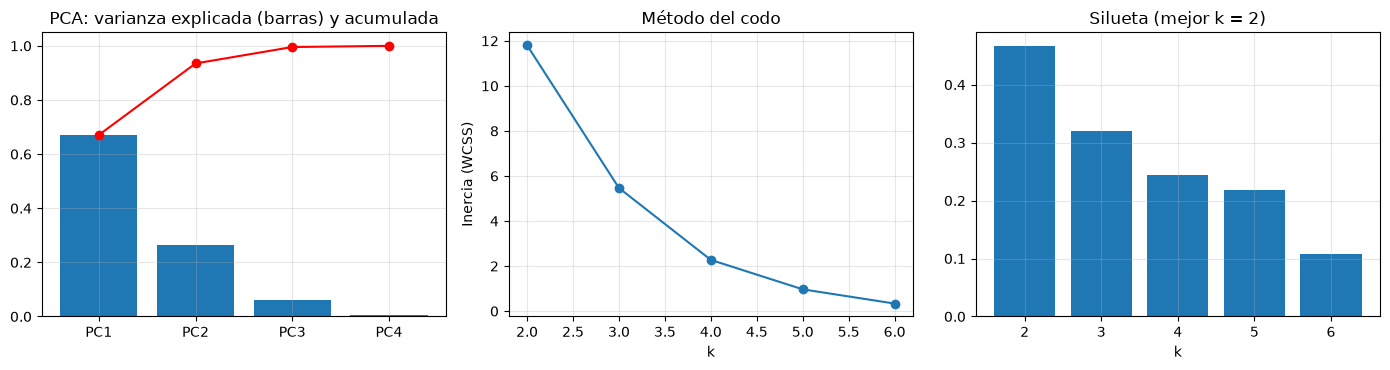

In [34]:
nombres_mun = panel.drop_duplicates("id_municipio")[["id_municipio", "municipio"]]
VARS_PERFIL = ["t_hist", "amp_hist", "var_t", "var_amp"]
perfil = (temp_ref[temp_ref["anio"] <= ANIO_TRAIN_MAX].groupby("id_municipio")
          .agg(t_hist=("t_hist", "first"), amp_hist=("amp_hist", "first"), var_t=("t_anom", "std"),
               var_amp=("amp_anom", "std"), clima_ord=("clima_ord", "first"))
          .reset_index().merge(nombres_mun, on="id_municipio", how="left")
          .dropna(subset=VARS_PERFIL).reset_index(drop=True))
assert len(perfil) >= 6, "Muy pocos municipios para agrupar"
Xp = StandardScaler().fit_transform(perfil[VARS_PERFIL])
print(f"Municipios en el perfil climático: {len(perfil)}")

# 1) PCA
pca_full = PCA().fit(Xp)
var_exp = pca_full.explained_variance_ratio_
pca_tab = pd.DataFrame({"componente": [f"PC{i + 1}" for i in range(len(var_exp))],
                        "varianza explicada": var_exp, "acumulada": np.cumsum(var_exp)})
cargas = pd.DataFrame(pca_full.components_[:2].T, index=VARS_PERFIL, columns=["PC1", "PC2"])
Zp = PCA(n_components=2).fit_transform(Xp)
display(pca_tab.style.format({"varianza explicada": "{:.1%}", "acumulada": "{:.1%}"}).hide(axis="index").set_caption("PCA del perfil climático"))
display(cargas.style.format("{:+.3f}").set_caption("Cargas de PC1 y PC2"))

# 2) Número de clústeres: codo y silueta
ks = list(range(2, min(K_MAX, len(perfil) - 1) + 1))
inercia, sil_k = [], []
for k_ in ks:
    km_ = KMeans(n_clusters=k_, n_init=10, random_state=SEMILLA).fit(Xp)
    inercia.append(km_.inertia_)
    sil_k.append(silhouette_score(Xp, km_.labels_))
K_OPT = ks[int(np.argmax(sil_k))]

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].bar(pca_tab["componente"], pca_tab["varianza explicada"]); axs[0].plot(pca_tab["componente"], pca_tab["acumulada"], "o-", color="red")
axs[0].set_title("PCA: varianza explicada (barras) y acumulada")
axs[1].plot(ks, inercia, "o-"); axs[1].set_title("Método del codo"); axs[1].set_xlabel("k"); axs[1].set_ylabel("Inercia (WCSS)")
axs[2].bar(ks, sil_k); axs[2].set_title(f"Silueta (mejor k = {K_OPT})"); axs[2].set_xlabel("k")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "clustering_pca_codo_silueta.png", dpi=150); plt.show()

Método,Clústeres,Ruido (DBSCAN),Silueta,Davies-Bouldin,Rand ajustado vs clima,Fowlkes-Mallows vs clima
k-means,2,0,0.467,0.298,-0.089,0.346
Jerárquico (Ward),2,0,0.467,0.298,-0.089,0.346
Espectral,2,0,0.185,1.172,-0.235,0.149
DBSCAN (eps=1.2),1,3,—,—,-0.029,0.298


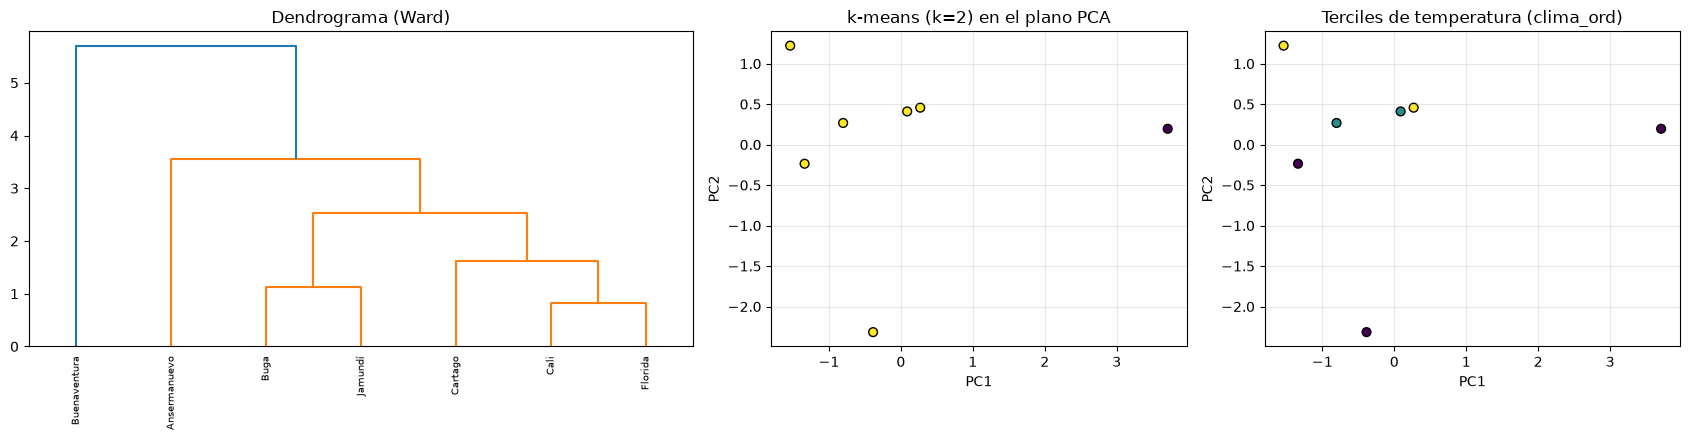

,municipios,t_hist,amp_hist,var_t,var_amp
cluster_kmeans,,,,,
0,1.00,21.79,10.44,5.12,8.53
1,6.00,21.54,3.46,0.94,3.11


In [35]:
# 3) Cuatro algoritmos de clustering
et_km = KMeans(n_clusters=K_OPT, n_init=10, random_state=SEMILLA).fit(Xp).labels_
et_ag = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward").fit(Xp).labels_
et_sp = SpectralClustering(n_clusters=K_OPT, affinity="rbf", assign_labels="discretize", random_state=SEMILLA).fit(Xp).labels_
et_db = DBSCAN(eps=1.2, min_samples=3).fit(Xp).labels_

# 4) Evaluación interna y externa
clima_real = perfil["clima_ord"].astype(int).to_numpy()
def evaluar_agrupamiento(nombre, etiquetas):
    et = np.asarray(etiquetas)
    valido = et != -1
    n_cl = len(set(et[valido]))
    out = {"Método": nombre, "Clústeres": n_cl, "Ruido (DBSCAN)": int((~valido).sum()), "Silueta": np.nan, "Davies-Bouldin": np.nan}
    if n_cl >= 2 and valido.sum() > n_cl:
        out["Silueta"] = silhouette_score(Xp[valido], et[valido])
        out["Davies-Bouldin"] = davies_bouldin_score(Xp[valido], et[valido])
    out["Rand ajustado vs clima"] = adjusted_rand_score(clima_real, et)
    out["Fowlkes-Mallows vs clima"] = fowlkes_mallows_score(clima_real, et)
    return out

ev_cl = pd.DataFrame([evaluar_agrupamiento("k-means", et_km), evaluar_agrupamiento("Jerárquico (Ward)", et_ag),
                      evaluar_agrupamiento("Espectral", et_sp), evaluar_agrupamiento("DBSCAN (eps=1.2)", et_db)])
display(ev_cl.style.format({"Silueta": "{:.3f}", "Davies-Bouldin": "{:.3f}", "Rand ajustado vs clima": "{:+.3f}",
                            "Fowlkes-Mallows vs clima": "{:.3f}"}, na_rep="—").hide(axis="index")
        .set_caption("Silueta alta y Davies-Bouldin bajo = clústeres compactos y separados; Rand/Fowlkes altos = coinciden con los terciles"))

# Dendrograma y mapa PCA
etiquetas_mun = perfil["municipio"].fillna(perfil["id_municipio"]).astype(str).tolist()
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})
dendrogram(linkage(Xp, method="ward"), labels=etiquetas_mun, leaf_rotation=90, leaf_font_size=7, ax=axs[0])
axs[0].set_title("Dendrograma (Ward)"); axs[0].grid(False)
for ax, et, titulo in [(axs[1], et_km, f"k-means (k={K_OPT}) en el plano PCA"), (axs[2], clima_real, "Terciles de temperatura (clima_ord)")]:
    sc_ = ax.scatter(Zp[:, 0], Zp[:, 1], c=et, cmap="viridis", s=40, edgecolor="k")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(titulo)
plt.tight_layout(); plt.savefig(CARPETA_FIG / "clustering_municipios.png", dpi=150); plt.show()

perfil_cl = perfil.assign(cluster_kmeans=et_km, cluster_jerarquico=et_ag, cluster_espectral=et_sp, cluster_dbscan=et_db)
display(perfil_cl.groupby("cluster_kmeans").agg(municipios=("id_municipio", "size"), t_hist=("t_hist", "mean"), amp_hist=("amp_hist", "mean"),
        var_t=("var_t", "mean"), var_amp=("var_amp", "mean")).style.format("{:.2f}").set_caption("Perfil promedio de cada clúster de k-means"))
ARI_KM = ev_cl.loc[0, "Rand ajustado vs clima"]; SIL_KM = ev_cl.loc[0, "Silueta"]

---
# 8. Interpretación del modelo (RA5)

Se explica el **modelo final** (`M2`, *gradient boosting* con clima completo) con dos herramientas complementarias:

- **Importancia por permutación (sobre prueba):** cuánto **empeora el MAE** al desordenar una variable. Es una medida global y honesta porque usa datos no vistos.
- **Valores SHAP:** cuánto empuja cada variable, registro a registro, la predicción hacia arriba o hacia abajo, y en qué sentido.

> **Cautela.** La importancia mide cuánto *usa* el modelo una variable, no que *cause* el rendimiento. Además, `t_hist` y `clima_ord` identifican al municipio, así que parte de su importancia es "geografía", no "temperatura del año".

,etiqueta,origen,aumento_MAE,desv
0,Rendimiento relativo del año anterior,Cultivos (Parte 1),+0.16160,0.01154
1,Anomalía de temperatura del año,Integración (IDEAM),+0.00052,0.00234
2,"Clase de clima (frío, templado, cálido)",Integración (IDEAM),+0.00000,0.00000
3,Hectáreas sembradas (log),Cultivos (Parte 1),-0.00018,0.00125
4,Anomalía de amplitud térmica,Integración (IDEAM),-0.00163,0.00343
5,Anomalía de temperatura del año anterior,Integración (IDEAM),-0.00167,0.00252
6,Cultivo permanente (1) o transitorio (0),Cultivos (Parte 1),-0.00201,0.00290
7,Temperatura normal del municipio,Integración (IDEAM),-0.00348,0.00127


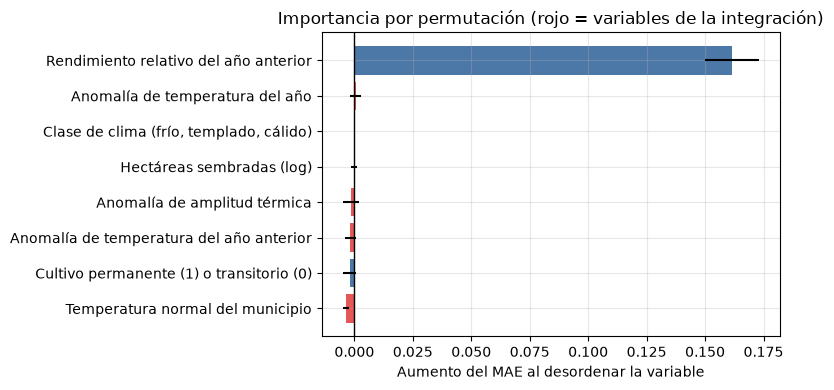

In [36]:
modelo_final = RES["M2 · Boosting + clima completo (F_COMPLETO)"]["modelo"]
X_te = te_df[F_COMPLETO]

perm = permutation_importance(modelo_final, X_te, y_te, scoring="neg_mean_absolute_error",
                              n_repeats=30, random_state=SEMILLA)
imp = (pd.DataFrame({"variable": F_COMPLETO, "aumento_MAE": perm.importances_mean, "desv": perm.importances_std})
       .assign(etiqueta=lambda t: t["variable"].map(ETIQUETAS),
               origen=lambda t: np.where(t["variable"].isin(["t_hist", "clima_ord", "t_anom", "t_anom_prev", "amp_anom"]),
                                         "Integración (IDEAM)", "Cultivos (Parte 1)"))
       .sort_values("aumento_MAE", ascending=False).reset_index(drop=True))
display(imp[["etiqueta", "origen", "aumento_MAE", "desv"]].style.format({"aumento_MAE": "{:+.5f}", "desv": "{:.5f}"})
        .set_caption("Importancia por permutación en prueba (aumento del MAE al desordenar la variable)"))

fig, ax = plt.subplots(figsize=(8, 4))
colores = imp["origen"].map({"Integración (IDEAM)": "#E45756", "Cultivos (Parte 1)": "#4C78A8"})
ax.barh(imp["etiqueta"], imp["aumento_MAE"], xerr=imp["desv"], color=colores)
ax.invert_yaxis(); ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Aumento del MAE al desordenar la variable")
ax.set_title("Importancia por permutación (rojo = variables de la integración)")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "importancia_permutacion.png", dpi=150); plt.show()

Background dataset has 150 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=150 when initializing the masker.
PermutationExplainer explainer: 311it [03:36,  1.36it/s]                         


,variable,mean_abs_shap,etiqueta
0,y_prev,0.19666,Rendimiento relativo del año anterior
1,t_anom_prev,0.02890,Anomalía de temperatura del año anterior
2,t_anom,0.02237,Anomalía de temperatura del año
3,amp_anom,0.02065,Anomalía de amplitud térmica
4,es_perm,0.01520,Cultivo permanente (1) o transitorio (0)
5,t_hist,0.00883,Temperatura normal del municipio
6,log_ha,0.00811,Hectáreas sembradas (log)
7,clima_ord,0.00000,"Clase de clima (frío, templado, cálido)"


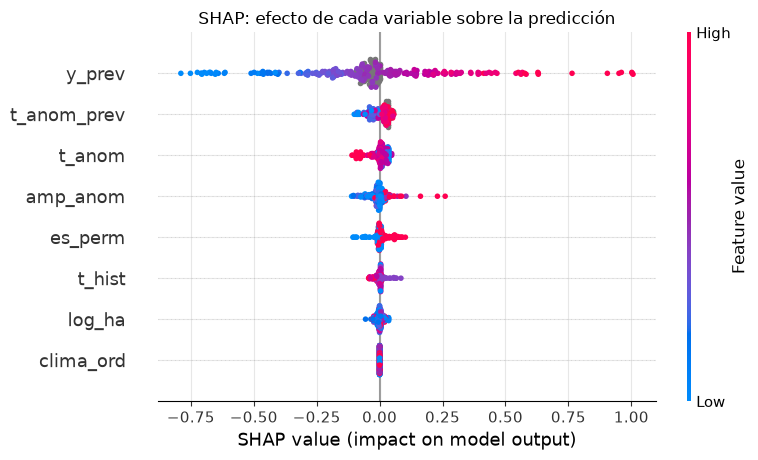

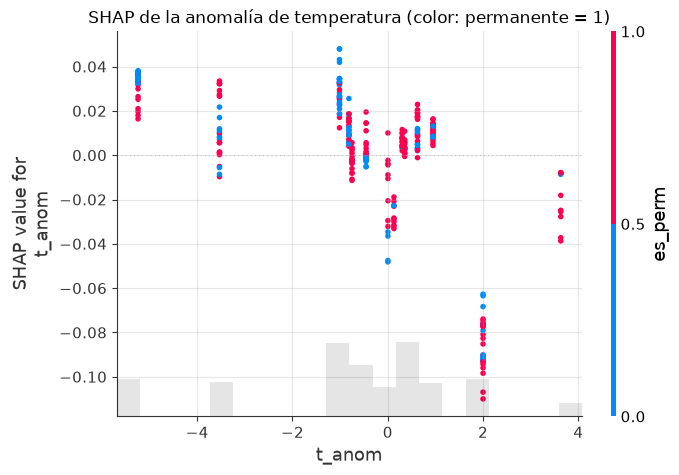

In [37]:
# SHAP: explicación registro a registro
try:
    import shap
    fondo = trva_df[F_COMPLETO].sample(min(150, len(trva_df)), random_state=SEMILLA)
    muestra = X_te.sample(min(400, len(X_te)), random_state=SEMILLA)
    explicador = shap.Explainer(modelo_final.predict, fondo, algorithm="permutation", seed=SEMILLA)
    sv = explicador(muestra)
    shap_resumen = (pd.DataFrame({"variable": F_COMPLETO, "mean_abs_shap": np.abs(sv.values).mean(0)})
                    .assign(etiqueta=lambda t: t["variable"].map(ETIQUETAS))
                    .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
    display(shap_resumen.style.format({"mean_abs_shap": "{:.5f}"}).set_caption("Importancia SHAP media absoluta (muestra de prueba)"))

    shap.plots.beeswarm(sv, show=False, max_display=len(F_COMPLETO))
    plt.title("SHAP: efecto de cada variable sobre la predicción"); plt.tight_layout()
    plt.savefig(CARPETA_FIG / "shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

    shap.plots.scatter(sv[:, "t_anom"], color=sv[:, "es_perm"], show=False)
    plt.title("SHAP de la anomalía de temperatura (color: permanente = 1)")
    plt.savefig(CARPETA_FIG / "shap_dependencia_t_anom.png", dpi=150, bbox_inches="tight"); plt.show()
    SHAP_OK = True
except ImportError:
    SHAP_OK = False
    shap_resumen = None
    print("shap no está instalado: se usa solo la importancia por permutación (pip install shap).")

In [38]:
# Lectura automática de la importancia
top = imp.iloc[0]
integ_imp = imp[imp["origen"] == "Integración (IDEAM)"]
anom_imp = imp[imp["variable"].isin(["t_anom", "t_anom_prev", "amp_anom"])]
display(Markdown(
    f"**Lectura.** La variable que más usa el modelo es *{top['etiqueta'].lower()}* "
    f"(+{top['aumento_MAE']:.5f} de MAE al desordenarla). Entre las variables de la integración, la más útil es "
    f"*{integ_imp.iloc[0]['etiqueta'].lower()}* (+{integ_imp.iloc[0]['aumento_MAE']:.5f}). "
    f"Las tres **anomalías del año** suman +{anom_imp['aumento_MAE'].clip(lower=0).sum():.5f} de MAE, frente a "
    f"+{imp['aumento_MAE'].clip(lower=0).sum():.5f} del total de variables: "
    f"{anom_imp['aumento_MAE'].clip(lower=0).sum() / max(imp['aumento_MAE'].clip(lower=0).sum(), 1e-12):.0%} "
    f"de la importancia total viene de cómo fue el año respecto a lo normal. "
    "Una importancia cercana a 0 o negativa significa que desordenar la variable no empeora el modelo en prueba."))

**Lectura.** La variable que más usa el modelo es *rendimiento relativo del año anterior* (+0.16160 de MAE al desordenarla). Entre las variables de la integración, la más útil es *anomalía de temperatura del año* (+0.00052). Las tres **anomalías del año** suman +0.00052 de MAE, frente a +0.16212 del total de variables: 0% de la importancia total viene de cómo fue el año respecto a lo normal. Una importancia cercana a 0 o negativa significa que desordenar la variable no empeora el modelo en prueba.

---
# 9. Contraste de hipótesis H1 a H5

Aquí se estima la **asociación** entre temperatura y rendimiento, no se predice. Se usan las anomalías originales de la Parte 2 (`t_anomalia`, `rend_anomalia`, `amplitud_anomalia`) sobre la base de análisis completa. Como el rendimiento ya está medido respecto a la normal de cada municipio-cultivo, los efectos fijos por municipio y cultivo quedan absorbidos.

**Cómo se prueba cada hipótesis**

- Regresión por mínimos cuadrados con **errores estándar agrupados por municipio** (los registros de un mismo municipio no son independientes: comparten temperatura y suelo).
- Todas las hipótesis predicen un coeficiente **negativo** (`Ha: β < 0`), por lo que se reporta el valor p **unilateral**.
- Los seis contrastes principales se corrigen por comparaciones múltiples (**Holm**).
- Con pocos municipios (conglomerados), los errores agrupados son aproximados; los valores p son orientativos.

> **Qué se agrega en 9.2 y 9.3.** En el Laboratorio 2 cada hipótesis traía su propia prueba (efectos fijos por municipio-cultivo, comparación de pendientes, Kruskal-Wallis, aporte del rezago por grupo, correlación de Spearman). La sección 9.2 las completa y la 9.3 repite la pregunta con el modelo: ¿qué tanto empeora la predicción en prueba si se quita la variable de la hipótesis?

In [39]:
inf = (integ[integ["en_base_analisis"]].dropna(subset=["t_anomalia", "rend_anomalia"]).copy())
inf["es_trans"] = (inf["grupo"] == "Transitorio").astype(int)
inf["es_perm"] = (inf["grupo"] == "Permanente").astype(int)
inf["clima_ord"] = inf["clima_municipio"].map({"Frío": 0, "Templado": 1, "Cálido": 2})
print(f"Base de inferencia: {len(inf):,} registros · {inf['id_municipio'].nunique()} municipios")

def ols_cluster(formula, cols):
    d = inf.dropna(subset=cols)
    m = smf.ols(formula, data=d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["id_municipio"])[0]})
    return m, len(d), d["id_municipio"].nunique()

def fila(hid, hipotesis, m, termino, n, g):
    b = m.params[termino]; lo, hi = m.conf_int().loc[termino]; p = m.pvalues[termino]
    p_uni = p / 2 if b < 0 else 1 - p / 2           # Ha: coeficiente < 0
    return {"ID": hid, "Hipótesis": hipotesis, "Término": termino, "β": b, "IC95 inf": lo, "IC95 sup": hi,
            "p bilateral": p, "p unilateral (Ha: β<0)": p_uni, "N": n, "Municipios": g}

filas = []
m, n, g = ols_cluster("rend_anomalia ~ t_anomalia", ["rend_anomalia", "t_anomalia"])
filas.append(fila("H1", "Año más cálido → menor rendimiento", m, "t_anomalia", n, g))
m, n, g = ols_cluster("rend_anomalia ~ t_anomalia * es_trans", ["rend_anomalia", "t_anomalia", "es_trans"])
filas.append(fila("H2", "Efecto más negativo en transitorios", m, "t_anomalia:es_trans", n, g))
m, n, g = ols_cluster("rend_anomalia ~ t_anomalia * clima_ord", ["rend_anomalia", "t_anomalia", "clima_ord"])
filas.append(fila("H3", "Efecto más negativo en municipios más cálidos", m, "t_anomalia:clima_ord", n, g))
m, n, g = ols_cluster("rend_anomalia ~ t_anomalia + t_anomalia_prev * es_perm",
                      ["rend_anomalia", "t_anomalia", "t_anomalia_prev", "es_perm"])
filas.append(fila("H4a", "Temperatura del año anterior → menor rendimiento", m, "t_anomalia_prev", n, g))
filas.append(fila("H4b", "…y más en permanentes", m, "t_anomalia_prev:es_perm", n, g))
m, n, g = ols_cluster("rend_anomalia ~ t_anomalia + amplitud_anomalia", ["rend_anomalia", "t_anomalia", "amplitud_anomalia"])
filas.append(fila("H5", "Mayor amplitud térmica → menor rendimiento", m, "amplitud_anomalia", n, g))

hip = pd.DataFrame(filas)
hip["p Holm"] = multipletests(hip["p unilateral (Ha: β<0)"], method="holm")[1]
hip["Decisión (α = %.2f)" % ALFA] = np.where(hip["p Holm"] < ALFA, "Se rechaza H0", "No se rechaza H0")
display(hip.style.format({"β": "{:+.4f}", "IC95 inf": "{:+.4f}", "IC95 sup": "{:+.4f}", "p bilateral": "{:.3g}",
                          "p unilateral (Ha: β<0)": "{:.3g}", "p Holm": "{:.3g}", "N": "{:,}"})
        .hide(axis="index").set_caption("Contraste de hipótesis con errores agrupados por municipio y corrección de Holm"))

# Complemento no paramétrico de H1: años cálidos vs fríos
cal = inf.loc[inf["t_anomalia"] > UMBRAL_CALIDO, "rend_anomalia"]
fri = inf.loc[inf["t_anomalia"] < -UMBRAL_CALIDO, "rend_anomalia"]
u = stats.mannwhitneyu(cal, fri, alternative="less")
mw = {"años cálidos (n)": len(cal), "años fríos (n)": len(fri), "mediana cálidos": cal.median(),
      "mediana fríos": fri.median(), "p Mann-Whitney (cálidos < fríos)": u.pvalue}
display(pd.Series(mw, name="H1 · Mann-Whitney").to_frame().T)

Base de inferencia: 4,860 registros · 13 municipios


ID,Hipótesis,Término,β,IC95 inf,IC95 sup,p bilateral,p unilateral (Ha: β<0),N,Municipios,p Holm,Decisión (α = 0.05)
H1,Año más cálido → menor rendimiento,t_anomalia,-0.0056,-0.0176,+0.0064,0.361,0.18,"4,860",13,1,No se rechaza H0
H2,Efecto más negativo en transitorios,t_anomalia:es_trans,-0.0082,-0.0446,+0.0283,0.66,0.33,"4,860",13,1,No se rechaza H0
H3,Efecto más negativo en municipios más cálidos,t_anomalia:clima_ord,-0.0106,-0.0420,+0.0207,0.506,0.253,"4,860",13,1,No se rechaza H0
H4a,Temperatura del año anterior → menor rendimiento,t_anomalia_prev,+0.0013,-0.0317,+0.0343,0.94,0.53,"4,189",13,1,No se rechaza H0
H4b,…y más en permanentes,t_anomalia_prev:es_perm,-0.0022,-0.0275,+0.0231,0.865,0.433,"4,189",13,1,No se rechaza H0
H5,Mayor amplitud térmica → menor rendimiento,amplitud_anomalia,-0.0007,-0.0094,+0.0081,0.879,0.44,"4,860",13,1,No se rechaza H0


,años cálidos (n),años fríos (n),mediana cálidos,mediana fríos,p Mann-Whitney (cálidos < fríos)
H1 · Mann-Whitney,1629.0,1032.0,-0.021667,-0.022008,0.321435


## 9.1 Evidencia exploratoria por cultivo (H6 y H8 de la Parte 2)

Estas dos nacieron de mirar los datos por cultivo, así que son **exploratorias**: se corrigen por comparaciones múltiples (Benjamini-Hochberg, FDR) y se leen como descriptivas, no como confirmación.

In [40]:
filas_c = []
for (grp, cult), d_ in inf.groupby(["grupo", "cultivo"]):
    if len(d_) >= MIN_OBS_CULTIVO:
        rho, p = stats.spearmanr(d_["t_anomalia"], d_["rend_anomalia"])
        filas_c.append({"grupo": grp, "cultivo": cult, "n": len(d_), "rho": rho, "p": p,
                        "t_media_cultivo": d_["t_media"].mean()})
por_cultivo = pd.DataFrame(filas_c)
if len(por_cultivo):
    por_cultivo["p_FDR"] = multipletests(por_cultivo["p"], method="fdr_bh")[1]
    por_cultivo = por_cultivo.sort_values("rho").reset_index(drop=True)
    display(por_cultivo.style.format({"rho": "{:+.3f}", "p": "{:.3g}", "p_FDR": "{:.3g}", "t_media_cultivo": "{:.1f}"})
            .hide(axis="index").set_caption("Spearman t_anomalia vs rend_anomalia por cultivo (n ≥ %d)" % MIN_OBS_CULTIVO))
    sig = por_cultivo[por_cultivo["p_FDR"] < ALFA]
    print(f"Cultivos con asociación significativa tras FDR: {len(sig)} de {len(por_cultivo)}")
    if len(por_cultivo) >= 5:
        r8, p8 = stats.spearmanr(por_cultivo["t_media_cultivo"], por_cultivo["rho"])
        print(f"H8 (¿el rho es más negativo en cultivos de zonas frías?): Spearman = {r8:+.2f}, p = {p8:.3g} "
              f"con {len(por_cultivo)} cultivos (muestra pequeña)")
else:
    print("Ningún cultivo alcanza el mínimo de observaciones.")

grupo,cultivo,n,rho,p,t_media_cultivo,p_FDR
Transitorio,Zanahoria,47,-0.353,0.015,22.1,0.231
Transitorio,Fríjol Ladera,126,-0.294,0.00083,21.7,0.0191
Transitorio,Repollo,59,-0.242,0.0645,22.6,0.487
Permanente,Arracacha,33,-0.223,0.212,22.1,0.63
Transitorio,Pepino,103,-0.194,0.0498,22.0,0.458
Permanente,Guanábana,81,-0.162,0.148,21.2,0.487
Permanente,Cítricos,111,-0.153,0.11,21.6,0.487
Transitorio,Pimentón,116,-0.137,0.142,21.4,0.487
Permanente,Tomate De Árbol,85,-0.131,0.233,21.8,0.63
Permanente,Curuba,42,-0.127,0.424,21.9,0.721


Cultivos con asociación significativa tras FDR: 2 de 46
H8 (¿el rho es más negativo en cultivos de zonas frías?): Spearman = -0.03, p = 0.848 con 46 cultivos (muestra pequeña)


## 9.2 Pruebas complementarias (H1 a H5)

Misma base de inferencia (`inf`) y mismos errores agrupados por municipio que en la sección 9. Estas pruebas **no entran en la corrección de Holm** del contraste principal: son evidencia de apoyo y se leen junto con él.

| Hipótesis | Prueba | Qué responde |
|---|---|---|
| H1 | Efectos fijos por municipio-cultivo-ciclo (estimador intra-grupo) | ¿Sigue el signo de `t_anomalia` cuando se compara cada municipio-cultivo solo consigo mismo? |
| H2 | Pendiente de `t_anomalia` por grupo (transitorio vs permanente) | ¿Es más negativa la pendiente en transitorios? |
| H3 | Pendiente por clima del municipio y **Kruskal-Wallis** del rendimiento relativo entre climas, en años cálidos | ¿Los años cálidos dejan peor rendimiento donde el clima normal ya es cálido? |
| H4 | Pendiente de `t_anomalia_prev` y ΔR² por grupo | ¿Cuánto explica el año anterior, y más en permanentes? |
| H5 | Correlación de Spearman entre `amplitud_anomalia` y `rend_anomalia` | ¿Hay asociación monótona con la amplitud térmica? |

ID,Prueba,Estrato,N,Municipios,Estimador,IC95 inf,IC95 sup,p bilateral,ΔR² por el rezago
H1,Efectos fijos municipio-cultivo-ciclo,Todos,"4,860",13,-0.0041,-0.0161,+0.0079,0.503,—
H2,Pendiente de t_anomalia por grupo,Permanente,"2,411",13,-0.0022,-0.0109,+0.0065,0.625,—
H2,Pendiente de t_anomalia por grupo,Transitorio,"2,449",13,-0.0103,-0.0413,+0.0206,0.513,—
H3,Pendiente de t_anomalia por clima,Frío,654,3,+0.0398,-0.1236,+0.2032,0.633,—
H3,Pendiente de t_anomalia por clima,Templado,"1,783",5,-0.0010,-0.0248,+0.0228,0.934,—
H3,Pendiente de t_anomalia por clima,Cálido,"2,423",5,-0.0073,-0.0219,+0.0074,0.331,—
H4,Pendiente de t_anomalia_prev por grupo,Permanente,"2,072",13,-0.0037,-0.0207,+0.0132,0.665,+0.00016
H4,Pendiente de t_anomalia_prev por grupo,Transitorio,"2,117",13,+0.0051,-0.0206,+0.0309,0.696,+0.00020
H5,Spearman amplitud_anomalia vs rend_anomalia,Todos,"4,860",13,+0.0185,—,—,0.197,—


Subconjunto,N,H de Kruskal-Wallis,p,mediana Cálido,mediana Frío,mediana Templado
Años cálidos (t_anomalia > +0.5),"1,629",4.61,0.1,-0.0112,-0.0217,-0.0600
Años fríos (t_anomalia < -0.5),"1,032",8.47,0.0145,-0.0094,-0.0635,-0.0563


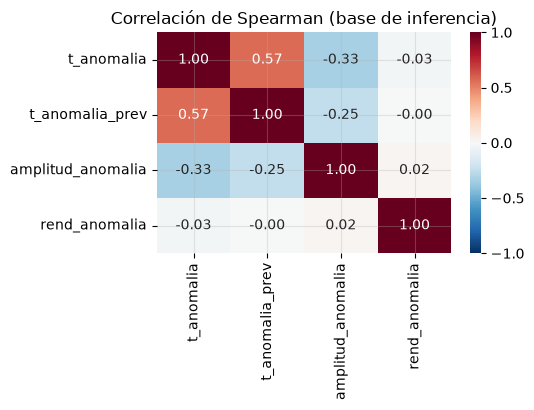

In [41]:
# 9.2 · Pruebas complementarias (misma base `inf` de la sección 9)
inf["mc"] = inf["id_municipio"] + "_" + inf["id_cultivo"] + "_" + inf["ciclo"].astype(str)
COLS_OK = ["rend_anomalia", "t_anomalia"]
MIN_MUN_ESTRATO = 3      # municipios mínimos para estimar una pendiente con errores agrupados

def ajustar_cl(formula, d):
    return smf.ols(formula, data=d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["id_municipio"])[0]})

def fila_c(hid, prueba, estrato, m, termino, d):
    b = m.params[termino]; lo, hi = m.conf_int().loc[termino]
    return {"ID": hid, "Prueba": prueba, "Estrato": estrato, "N": len(d), "Municipios": d["id_municipio"].nunique(),
            "Estimador": b, "IC95 inf": lo, "IC95 sup": hi, "p bilateral": m.pvalues[termino], "ΔR² por el rezago": np.nan}

filas_c = []

# H1 · efectos fijos por municipio-cultivo-ciclo (se resta la media de cada grupo: estimador intra-grupo)
d1 = inf.dropna(subset=COLS_OK).copy()
for c_ in COLS_OK:
    d1[c_ + "_w"] = d1[c_] - d1.groupby("mc")[c_].transform("mean")
filas_c.append(fila_c("H1", "Efectos fijos municipio-cultivo-ciclo", "Todos",
                      ajustar_cl("rend_anomalia_w ~ 0 + t_anomalia_w", d1), "t_anomalia_w", d1))

# H2 · pendiente por grupo de cultivo
for g_, dg in inf.dropna(subset=COLS_OK).groupby("grupo"):
    if dg["id_municipio"].nunique() >= MIN_MUN_ESTRATO:
        filas_c.append(fila_c("H2", "Pendiente de t_anomalia por grupo", g_,
                              ajustar_cl("rend_anomalia ~ t_anomalia", dg), "t_anomalia", dg))

# H3 · pendiente por clima del municipio
for cl_ in ["Frío", "Templado", "Cálido"]:
    dg = inf.dropna(subset=COLS_OK)[lambda t: t["clima_municipio"] == cl_]
    if dg["id_municipio"].nunique() >= MIN_MUN_ESTRATO:
        filas_c.append(fila_c("H3", "Pendiente de t_anomalia por clima", cl_,
                              ajustar_cl("rend_anomalia ~ t_anomalia", dg), "t_anomalia", dg))

# H4 · aporte del rezago por grupo (pendiente del rezago y ΔR² frente al modelo sin rezago)
for g_, dg in inf.dropna(subset=COLS_OK + ["t_anomalia_prev"]).groupby("grupo"):
    if dg["id_municipio"].nunique() >= MIN_MUN_ESTRATO:
        m0 = ajustar_cl("rend_anomalia ~ t_anomalia", dg)
        m1_ = ajustar_cl("rend_anomalia ~ t_anomalia + t_anomalia_prev", dg)
        f = fila_c("H4", "Pendiente de t_anomalia_prev por grupo", g_, m1_, "t_anomalia_prev", dg)
        f["ΔR² por el rezago"] = m1_.rsquared - m0.rsquared
        filas_c.append(f)

# H5 · correlación de Spearman con la amplitud térmica
d5 = inf.dropna(subset=["rend_anomalia", "amplitud_anomalia"])
rho5, p5 = stats.spearmanr(d5["amplitud_anomalia"], d5["rend_anomalia"])
filas_c.append({"ID": "H5", "Prueba": "Spearman amplitud_anomalia vs rend_anomalia", "Estrato": "Todos", "N": len(d5),
                "Municipios": d5["id_municipio"].nunique(), "Estimador": rho5, "IC95 inf": np.nan, "IC95 sup": np.nan,
                "p bilateral": p5, "ΔR² por el rezago": np.nan})

comp_tab = pd.DataFrame(filas_c)
display(comp_tab.style.format({"Estimador": "{:+.4f}", "IC95 inf": "{:+.4f}", "IC95 sup": "{:+.4f}", "p bilateral": "{:.3g}",
                               "ΔR² por el rezago": "{:+.5f}", "N": "{:,}"}, na_rep="—")
        .hide(axis="index").set_caption("Pruebas complementarias por hipótesis (errores agrupados por municipio)"))

# H3 · Kruskal-Wallis del rendimiento relativo entre climas, en años cálidos (y en fríos, como contraste)
filas_kw = []
for etiqueta, sub in [(f"Años cálidos (t_anomalia > +{UMBRAL_CALIDO})", inf[inf["t_anomalia"] > UMBRAL_CALIDO]),
                      (f"Años fríos (t_anomalia < -{UMBRAL_CALIDO})", inf[inf["t_anomalia"] < -UMBRAL_CALIDO])]:
    gr = {k: v["rend_anomalia"].to_numpy() for k, v in sub.groupby("clima_municipio") if len(v) >= 5}
    if len(gr) >= 2:
        Hs, pk = stats.kruskal(*gr.values())
        fila_ = {"Subconjunto": etiqueta, "N": sum(len(v) for v in gr.values()), "H de Kruskal-Wallis": Hs, "p": pk}
        for k, v in gr.items():
            fila_["mediana " + k] = np.median(v)
        filas_kw.append(fila_)
kw_tab = pd.DataFrame(filas_kw)
if len(kw_tab):
    fmt_kw = {c_: "{:+.4f}" for c_ in kw_tab.columns if c_.startswith("mediana")}
    fmt_kw.update({"H de Kruskal-Wallis": "{:.2f}", "p": "{:.3g}", "N": "{:,}"})
    display(kw_tab.style.format(fmt_kw, na_rep="—").hide(axis="index")
            .set_caption("H3 · Kruskal-Wallis: ¿cambia el rendimiento relativo entre climas del municipio?"))

# Matriz de correlación de Spearman (la misma figura del §6.4 del Laboratorio 2)
VARS_SP = ["t_anomalia", "t_anomalia_prev", "amplitud_anomalia", "rend_anomalia"]
sp = inf[VARS_SP].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(sp, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlación de Spearman (base de inferencia)")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "spearman_hipotesis.png", dpi=150); plt.show()

# Texto resumido por hipótesis (lo usa la síntesis de la sección 10)
def _ic(r): return f"{r['Estimador']:+.4f} (IC95 % {r['IC95 inf']:+.4f} a {r['IC95 sup']:+.4f}; p = {r['p bilateral']:.3g})"
comp_txt = {}
for hid in ["H1", "H2", "H3", "H4"]:
    sub = comp_tab[comp_tab["ID"] == hid]
    comp_txt[hid] = "; ".join(f"{r['Estrato']}: {_ic(r)}" for _, r in sub.iterrows()) or "sin datos suficientes"
comp_txt["H5"] = f"Spearman ρ = {rho5:+.3f} (p = {p5:.3g}, N = {len(d5):,})"
if len(kw_tab):
    r_c = kw_tab.iloc[0]
    comp_txt["H3"] += f"; Kruskal-Wallis en años cálidos: H = {r_c['H de Kruskal-Wallis']:.2f}, p = {r_c['p']:.3g}"
comp_txt["H4"] += "; ΔR² por grupo: " + ", ".join(
    f"{r['Estrato']} {r['ΔR² por el rezago']:+.5f}" for _, r in comp_tab[comp_tab["ID"] == "H4"].iterrows())

## 9.3 Prueba con modelo por hipótesis: ablación y submuestras

La sección 9 contrasta asociaciones. Aquí se hace la pregunta **predictiva** de cada hipótesis con el modelo final (M2), siempre en el conjunto de **prueba** y con el mismo *bootstrap* por municipio-año de la sección 7:

- **Ablación (H1, H4, H5):** se reentrena M2 (mismos hiperparámetros, entrenamiento + validación) **sin** la variable de la hipótesis y se mide cuánto sube el error. Δ = MAE(sin la variable) − MAE(M2); **Δ > 0 significa que la variable ayuda**.
- **Submuestras (H2, H3):** ΔMAE de M2 frente a M1 (que no ve las anomalías del año) **solo en transitorios, solo en permanentes y por clima**. Si H2 es cierta, la ayuda debería ser mayor en transitorios; si H3 es cierta, en municipios cálidos.

> Cuidado con las submuestras: la prueba tiene pocos registros y pocos municipios, así que los intervalos serán anchos. Un intervalo que incluye el 0 no prueba que no haya efecto, solo que no se distingue del ruido.

Hipótesis,Se quita,Δ MAE (sin − con),IC95 inferior,IC95 superior,La variable ayuda
H1,t_anom,-0.00163,-0.01412,+0.01001,No distinguible
H4,t_anom_prev,-0.00049,-0.00942,+0.00735,No distinguible
H5,amp_anom,-0.00310,-0.00954,+0.00381,No distinguible
H1+H4+H5,las 3 anomalías,-0.00918,-0.02666,+0.00707,No distinguible


Hipótesis,Submuestra,Registros,Δ MAE (M1 − M2),IC95 inferior,IC95 superior,Las anomalías ayudan
H2,Permanente,196,-0.02232,-0.04279,-0.00213,No distinguible
H2,Transitorio,114,-0.02015,-0.05616,+0.01358,No distinguible
H3,Frío,92,+0.00234,-0.01008,+0.01532,No distinguible
H3,Templado,119,—,—,—,Pocos datos
H3,Cálido,99,-0.01870,-0.04928,+0.00499,No distinguible


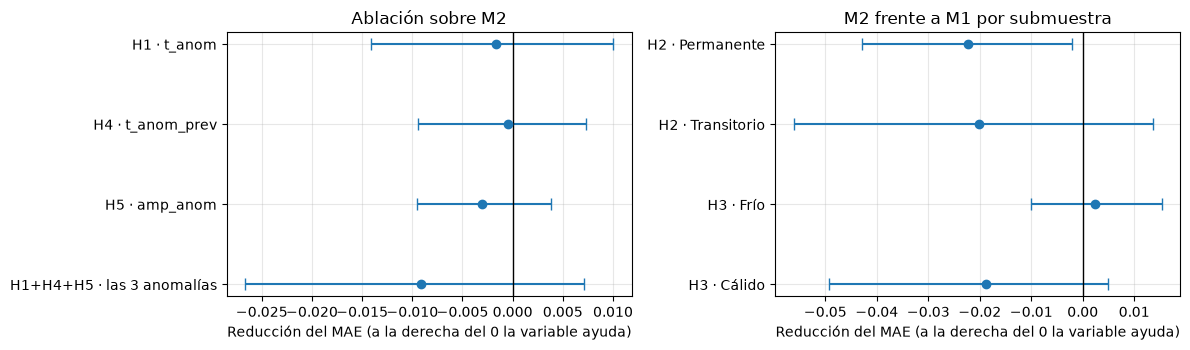

In [42]:
# 9.3 · Ablación por hipótesis y submuestras (conjunto de prueba)
nombre_m2 = "M2 · Boosting + clima completo (F_COMPLETO)"
p2 = RES[nombre_m2]["params"]

def pred_sin(quitar):
    feats = [f for f in F_COMPLETO if f not in quitar]
    m = hacer_modelo("hgb", p2).fit(trva_df[feats], trva_df["y"])
    return m.predict(te_df[feats])

EV_MODELO = {}     # hipótesis -> (Δ MAE, IC95 inf, IC95 sup)

# --- Ablación
ABLACIONES = [("H1", "t_anom", ["t_anom"]), ("H4", "t_anom_prev", ["t_anom_prev"]),
              ("H5", "amp_anom", ["amp_anom"]), ("H1+H4+H5", "las 3 anomalías", ["t_anom", "t_anom_prev", "amp_anom"])]
filas_a = []
for hid, etiqueta, quitar in ABLACIONES:
    d_, lo, hi = bootstrap_delta(y_arr, pred_sin(quitar), M2, cluster)
    filas_a.append({"Hipótesis": hid, "Se quita": etiqueta, "Δ MAE (sin − con)": d_, "IC95 inferior": lo,
                    "IC95 superior": hi, "La variable ayuda": "Sí" if lo > 0 else "No distinguible"})
    if hid in ("H1", "H4", "H5"):
        EV_MODELO[hid] = (d_, lo, hi)
abl_tab = pd.DataFrame(filas_a)
display(abl_tab.style.format({"Δ MAE (sin − con)": "{:+.5f}", "IC95 inferior": "{:+.5f}", "IC95 superior": "{:+.5f}"})
        .hide(axis="index").set_caption("Ablación sobre M2 (Δ > 0: quitar la variable empeora la predicción)"))

# --- Submuestras: M2 frente a M1
filas_s = []
def delta_sub(hid, etiqueta, mask):
    mask = np.asarray(mask)
    if mask.sum() < 30 or len(set(cluster[mask])) < 5:
        filas_s.append({"Hipótesis": hid, "Submuestra": etiqueta, "Registros": int(mask.sum()), "Δ MAE (M1 − M2)": np.nan,
                        "IC95 inferior": np.nan, "IC95 superior": np.nan, "Las anomalías ayudan": "Pocos datos"})
        return (np.nan, np.nan, np.nan)
    d_, lo, hi = bootstrap_delta(y_arr[mask], M1[mask], M2[mask], cluster[mask])
    filas_s.append({"Hipótesis": hid, "Submuestra": etiqueta, "Registros": int(mask.sum()), "Δ MAE (M1 − M2)": d_,
                    "IC95 inferior": lo, "IC95 superior": hi, "Las anomalías ayudan": "Sí" if lo > 0 else "No distinguible"})
    return (d_, lo, hi)

for g_ in ["Permanente", "Transitorio"]:
    r_ = delta_sub("H2", g_, (te_df["grupo"] == g_).to_numpy())
    if g_ == "Transitorio":
        EV_MODELO["H2"] = r_
for k_, etiqueta in {0: "Frío", 1: "Templado", 2: "Cálido"}.items():
    r_ = delta_sub("H3", etiqueta, (te_df["clima_ord"] == k_).to_numpy())
    if k_ == 2:
        EV_MODELO["H3"] = r_
sub_tab = pd.DataFrame(filas_s)
display(sub_tab.style.format({"Δ MAE (M1 − M2)": "{:+.5f}", "IC95 inferior": "{:+.5f}", "IC95 superior": "{:+.5f}"}, na_rep="—")
        .hide(axis="index").set_caption("M2 frente a M1 por submuestra de prueba (Δ > 0: las anomalías del año ayudan)"))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, tab, col, titulo in [(axs[0], abl_tab, "Δ MAE (sin − con)", "Ablación sobre M2"),
                             (axs[1], sub_tab.dropna(subset=["Δ MAE (M1 − M2)"]), "Δ MAE (M1 − M2)", "M2 frente a M1 por submuestra")]:
    etiquetas = (tab["Hipótesis"] + " · " + (tab["Se quita"] if "Se quita" in tab else tab["Submuestra"])).tolist()
    ax.errorbar(tab[col], range(len(tab)), xerr=[tab[col] - tab["IC95 inferior"], tab["IC95 superior"] - tab[col]], fmt="o", capsize=4)
    ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(tab))); ax.set_yticklabels(etiquetas); ax.invert_yaxis()
    ax.set_title(titulo); ax.set_xlabel("Reducción del MAE (a la derecha del 0 la variable ayuda)")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "ablacion_hipotesis.png", dpi=150); plt.show()

faltan_ev = [h_ for h_ in ["H1", "H2", "H3", "H4", "H5"] if h_ not in EV_MODELO]
assert not faltan_ev, f"Falta la evidencia de modelo para {faltan_ev}"

---
# 10. Síntesis: hipótesis frente a modelos

Se cruzan los dos tipos de evidencia: el contraste estadístico (sección 9) y lo que hace el modelo predictivo (secciones 6 a 8). Una hipótesis queda **bien respaldada** solo si ambos apuntan en la misma dirección.

**Regla del veredicto (se aplica en la celda siguiente).** *Respaldada por ambas pruebas* si el contraste estadístico rechaza H0 tras Holm **y** la prueba con modelo mejora con intervalo *bootstrap* por encima de 0; *respaldo parcial* si solo ocurre una; *sin respaldo con estos datos* si ninguna. "Sin respaldo" no demuestra que el efecto no exista: indica que estos datos no lo distinguen del ruido.

In [43]:
h = hip.set_index("ID")
RECHAZA = "Se rechaza H0"

def rango(var, tabla, col):
    t = tabla.sort_values(col, ascending=False).reset_index(drop=True)
    return int(t.index[t["variable"] == var][0]) + 1

def dec(i): return h.loc[i, "Decisión (α = %.2f)" % ALFA]
def txt_beta(i): return f"β = {h.loc[i, 'β']:+.4f} (IC95 % {h.loc[i, 'IC95 inf']:+.4f} a {h.loc[i, 'IC95 sup']:+.4f})"
def txt_ev(i):
    d_, lo, hi = EV_MODELO[i]
    return "sin datos" if d_ != d_ else f"Δ MAE = {d_:+.5f} (IC95 % {lo:+.5f} a {hi:+.5f})"
def ayuda(i): return EV_MODELO[i][1] > 0          # límite inferior del IC por encima de 0 (False si es NaN)
def veredicto(stat_ok, mod_ok):
    if stat_ok and mod_ok: return "Respaldada por ambas pruebas"
    if stat_ok: return "Respaldo parcial (solo la prueba estadística)"
    if mod_ok: return "Respaldo parcial (solo el modelo)"
    return "Sin respaldo con estos datos"

rango_perm_amp = rango("amp_anom", imp, "aumento_MAE")
rango_shap_amp = rango("amp_anom", shap_resumen, "mean_abs_shap") if shap_resumen is not None else None
delta_hip = boot_tab.loc["M2 vs M1 (anomalías del año)"]

filas_s = [
    {"ID": "H1", "Hipótesis": "H1 · Año cálido → menor rendimiento",
     "Prueba estadística": f"{dec('H1')}; {txt_beta('H1')}. Complemento: {comp_txt['H1']}",
     "Prueba con modelo": f"M2 vs M1: {delta_hip['Δ MAE (ref − modelo)']:+.5f} (IC95 % {delta_hip['IC95 inferior']:+.5f} a {delta_hip['IC95 superior']:+.5f}). Ablación sin t_anom: {txt_ev('H1')}",
     "Veredicto": veredicto(dec("H1") == RECHAZA, ayuda("H1"))},
    {"ID": "H2", "Hipótesis": "H2 · Más fuerte en transitorios",
     "Prueba estadística": f"{dec('H2')}; {txt_beta('H2')}. Complemento: {comp_txt['H2']}",
     "Prueba con modelo": f"Ayuda de las anomalías en transitorios: {txt_ev('H2')}",
     "Veredicto": veredicto(dec("H2") == RECHAZA, ayuda("H2"))},
    {"ID": "H3", "Hipótesis": "H3 · Más fuerte en municipios cálidos",
     "Prueba estadística": f"{dec('H3')}; {txt_beta('H3')}. Complemento: {comp_txt['H3']}",
     "Prueba con modelo": f"Ayuda de las anomalías en clima cálido: {txt_ev('H3')}",
     "Veredicto": veredicto(dec("H3") == RECHAZA, ayuda("H3"))},
    {"ID": "H4", "Hipótesis": "H4 · Temperatura del año anterior",
     "Prueba estadística": f"{dec('H4a')} (general); {dec('H4b')} (en permanentes). Complemento: {comp_txt['H4']}",
     "Prueba con modelo": f"Ablación sin t_anom_prev: {txt_ev('H4')}. Importancia: puesto {rango('t_anom_prev', imp, 'aumento_MAE')} de {len(imp)} (permutación)",
     "Veredicto": veredicto(RECHAZA in (dec("H4a"), dec("H4b")), ayuda("H4"))},
    {"ID": "H5", "Hipótesis": "H5 · Mayor amplitud térmica",
     "Prueba estadística": f"{dec('H5')}; {txt_beta('H5')}. Complemento: {comp_txt['H5']}",
     "Prueba con modelo": f"Ablación sin amp_anom: {txt_ev('H5')}. Importancia: puesto {rango_perm_amp} de {len(imp)} (permutación)"
                          + (f" y {rango_shap_amp} de {len(shap_resumen)} (SHAP)" if rango_shap_amp else ""),
     "Veredicto": veredicto(dec("H5") == RECHAZA, ayuda("H5"))},
]
sintesis = pd.DataFrame(filas_s)
display(sintesis.set_index("ID").style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
        .set_caption("Síntesis de hipótesis: contraste estadístico frente a prueba con modelo"))
display(sintesis[["Hipótesis", "Veredicto"]].style.hide(axis="index").set_properties(**{"text-align": "left"}))

,Hipótesis,Prueba estadística,Prueba con modelo,Veredicto
ID,,,,
H1,H1 · Año cálido → menor rendimiento,No se rechaza H0; β = -0.0056 (IC95 % -0.0176 a +0.0064). Complemento: Todos: -0.0041 (IC95 % -0.0161 a +0.0079; p = 0.503),M2 vs M1: -0.02152 (IC95 % -0.04311 a +0.00079). Ablación sin t_anom: Δ MAE = -0.00163 (IC95 % -0.01412 a +0.01001),Sin respaldo con estos datos
H2,H2 · Más fuerte en transitorios,No se rechaza H0; β = -0.0082 (IC95 % -0.0446 a +0.0283). Complemento: Permanente: -0.0022 (IC95 % -0.0109 a +0.0065; p = 0.625); Transitorio: -0.0103 (IC95 % -0.0413 a +0.0206; p = 0.513),Ayuda de las anomalías en transitorios: Δ MAE = -0.02015 (IC95 % -0.05616 a +0.01358),Sin respaldo con estos datos
H3,H3 · Más fuerte en municipios cálidos,"No se rechaza H0; β = -0.0106 (IC95 % -0.0420 a +0.0207). Complemento: Frío: +0.0398 (IC95 % -0.1236 a +0.2032; p = 0.633); Templado: -0.0010 (IC95 % -0.0248 a +0.0228; p = 0.934); Cálido: -0.0073 (IC95 % -0.0219 a +0.0074; p = 0.331); Kruskal-Wallis en años cálidos: H = 4.61, p = 0.1",Ayuda de las anomalías en clima cálido: Δ MAE = -0.01870 (IC95 % -0.04928 a +0.00499),Sin respaldo con estos datos
H4,H4 · Temperatura del año anterior,"No se rechaza H0 (general); No se rechaza H0 (en permanentes). Complemento: Permanente: -0.0037 (IC95 % -0.0207 a +0.0132; p = 0.665); Transitorio: +0.0051 (IC95 % -0.0206 a +0.0309; p = 0.696); ΔR² por grupo: Permanente +0.00016, Transitorio +0.00020",Ablación sin t_anom_prev: Δ MAE = -0.00049 (IC95 % -0.00942 a +0.00735). Importancia: puesto 6 de 8 (permutación),Sin respaldo con estos datos
H5,H5 · Mayor amplitud térmica,"No se rechaza H0; β = -0.0007 (IC95 % -0.0094 a +0.0081). Complemento: Spearman ρ = +0.018 (p = 0.197, N = 4,860)",Ablación sin amp_anom: Δ MAE = -0.00310 (IC95 % -0.00954 a +0.00381). Importancia: puesto 5 de 8 (permutación) y 4 de 8 (SHAP),Sin respaldo con estos datos


Hipótesis,Veredicto
H1 · Año cálido → menor rendimiento,Sin respaldo con estos datos
H2 · Más fuerte en transitorios,Sin respaldo con estos datos
H3 · Más fuerte en municipios cálidos,Sin respaldo con estos datos
H4 · Temperatura del año anterior,Sin respaldo con estos datos
H5 · Mayor amplitud térmica,Sin respaldo con estos datos


---
# 11. Guardar las salidas para el tablero y el resumen ejecutivo

El tablero de Streamlit **no** vuelve a entrenar ni descarga datos crudos: lee estos archivos pequeños. Se guardan en `data/procesados/tablero/` (`utf-8-sig`).

| Archivo | Contenido | Página del tablero |
|---|---|---|
| `metricas_modelos.csv` | Línea base y modelos, validación y prueba | Modelo |
| `predicciones_prueba.csv` | Real y predicho de cada registro de prueba (B0, B2, M1, M2) | Modelo |
| `importancia_permutacion.csv`, `shap_resumen.csv` | Importancia de variables | Interpretación |
| `hipotesis_resultados.csv`, `evidencia_cultivo.csv` | Contrastes H1-H5 y Spearman por cultivo | Interpretación |
| `base_modelado.csv` | Base con variables sin fuga | Explorador |
| `modelo_final.joblib` | Modelo entrenado (**no subir al repositorio**) | Opcional |
| `vif_multicolinealidad.csv` | VIF de las variables de los modelos lineales (Cap. 9) | Modelo |
| `metricas_clasificacion.csv` | Naive Bayes, árbol, KNN, SVM y logística (Cap. 10) | Modelo |
| `clusters_municipios.csv` | Perfil climático y clúster de cada municipio (Cap. 11) | Explorador |

In [44]:
metricas_out = tabla.reset_index()
metricas_out.to_csv(CARPETA_TABLERO / "metricas_modelos.csv", index=False, encoding="utf-8-sig")

pred_out = te_df[["anio", "id_municipio", "municipio", "cultivo", "grupo", "y"]].rename(columns={"y": "y_real"}).copy()
pred_out["pred_B0"] = RES["B0 · Promedio del entrenamiento"]["pred"]
pred_out["pred_B2"] = B2
pred_out["pred_M1"] = M1
pred_out["pred_M2"] = M2
pred_out.to_csv(CARPETA_TABLERO / "predicciones_prueba.csv", index=False, encoding="utf-8-sig")

imp.to_csv(CARPETA_TABLERO / "importancia_permutacion.csv", index=False, encoding="utf-8-sig")
if shap_resumen is not None:
    shap_resumen.to_csv(CARPETA_TABLERO / "shap_resumen.csv", index=False, encoding="utf-8-sig")
hip.to_csv(CARPETA_TABLERO / "hipotesis_resultados.csv", index=False, encoding="utf-8-sig")
por_cultivo.to_csv(CARPETA_TABLERO / "evidencia_cultivo.csv", index=False, encoding="utf-8-sig")
cols_base = ["anio", "id_municipio", "municipio", "subregion", "grupo", "cultivo", "split", "y"] + F_COMPLETO
modelo_df[cols_base].to_csv(CARPETA_TABLERO / "base_modelado.csv", index=False, encoding="utf-8-sig")
joblib.dump(modelo_final, CARPETA_TABLERO / "modelo_final.joblib")
vif_tab.to_csv(CARPETA_TABLERO / "vif_multicolinealidad.csv", encoding="utf-8-sig")
clf_tab.to_csv(CARPETA_TABLERO / "metricas_clasificacion.csv", index=False, encoding="utf-8-sig")
perfil_cl.to_csv(CARPETA_TABLERO / "clusters_municipios.csv", index=False, encoding="utf-8-sig")

comp_tab.to_csv(CARPETA_TABLERO / "hipotesis_complementarias.csv", index=False, encoding="utf-8-sig")
kw_tab.to_csv(CARPETA_TABLERO / "kruskal_wallis_clima.csv", index=False, encoding="utf-8-sig")
abl_tab.to_csv(CARPETA_TABLERO / "ablacion_hipotesis.csv", index=False, encoding="utf-8-sig")
sub_tab.to_csv(CARPETA_TABLERO / "delta_por_subgrupo.csv", index=False, encoding="utf-8-sig")
sintesis.to_csv(CARPETA_TABLERO / "sintesis_hipotesis.csv", index=False, encoding="utf-8-sig")

for f in sorted(CARPETA_TABLERO.iterdir()):
    print(f"Guardado: {f} ({f.stat().st_size / 1e6:.2f} MB)")

Guardado: data\procesados\tablero\ablacion_hipotesis.csv (0.00 MB)
Guardado: data\procesados\tablero\base_modelado.csv (0.62 MB)
Guardado: data\procesados\tablero\clusters_municipios.csv (0.00 MB)
Guardado: data\procesados\tablero\delta_por_subgrupo.csv (0.00 MB)
Guardado: data\procesados\tablero\evidencia_cultivo.csv (0.00 MB)
Guardado: data\procesados\tablero\hipotesis_complementarias.csv (0.00 MB)
Guardado: data\procesados\tablero\hipotesis_resultados.csv (0.00 MB)
Guardado: data\procesados\tablero\importancia_permutacion.csv (0.00 MB)
Guardado: data\procesados\tablero\kruskal_wallis_clima.csv (0.00 MB)
Guardado: data\procesados\tablero\metricas_clasificacion.csv (0.00 MB)
Guardado: data\procesados\tablero\metricas_modelos.csv (0.00 MB)
Guardado: data\procesados\tablero\modelo_final.joblib (0.41 MB)
Guardado: data\procesados\tablero\predicciones_prueba.csv (0.04 MB)
Guardado: data\procesados\tablero\shap_resumen.csv (0.00 MB)
Guardado: data\procesados\tablero\sintesis_hipotesis.csv 

---
# 12. Validación final

Igual que en las partes anteriores, se valida el **archivo guardado**, no las variables en memoria. Si la celda termina sin error, todas las pruebas pasaron.

In [45]:
pred_chk = pd.read_csv(CARPETA_TABLERO / "predicciones_prueba.csv", dtype={"id_municipio": str})
met_chk = pd.read_csv(CARPETA_TABLERO / "metricas_modelos.csv")
base_chk = pd.read_csv(CARPETA_TABLERO / "base_modelado.csv", dtype={"id_municipio": str})

# Partición temporal sin solapamiento
assert tr_df["anio"].max() < va_df["anio"].min() <= va_df["anio"].max() < te_df["anio"].min(), "Los conjuntos se solapan en el tiempo"
assert set(tr_df["anio"]).isdisjoint(set(te_df["anio"])), "Hay años en entrenamiento y prueba"
assert base_chk.groupby("split")["anio"].agg(["min", "max"]).loc["entrenamiento", "max"] <= ANIO_TRAIN_MAX

# Los modelos finales usan variables de la integración (exigencia de la rúbrica)
VARS_INTEGRACION = {"t_hist", "clima_ord", "t_anom", "t_anom_prev", "amp_anom"}
assert VARS_INTEGRACION <= set(RES["M2 · Boosting + clima completo (F_COMPLETO)"]["features"]), "M2 no usa la integración"
assert not (VARS_INTEGRACION & set(RES["B2 · Boosting sin integración (F_BASE)"]["features"])), "B2 no debe usar la integración"

# Sin faltantes en el objetivo, predicciones completas y finitas
assert base_chk["y"].notna().all()
assert pred_chk[["y_real", "pred_B0", "pred_B2", "pred_M1", "pred_M2"]].notna().all().all()
assert np.isfinite(pred_chk[["pred_B2", "pred_M1", "pred_M2"]].to_numpy()).all()
assert len(pred_chk) == len(te_df)
assert pred_chk["id_municipio"].str.fullmatch(r"76\d{3}").all(), "DIVIPOLA inválido"

# Coherencia entre archivo y memoria
mae_chk = (pred_chk["y_real"] - pred_chk["pred_M2"]).abs().mean()
assert abs(mae_chk - RES["M2 · Boosting + clima completo (F_COMPLETO)"]["test"]["MAE"]) < 1e-9, "El MAE guardado no coincide"
assert set(met_chk["Modelo"]) == set(RES)

# Capítulos 9-11: salidas nuevas
clf_chk = pd.read_csv(CARPETA_TABLERO / "metricas_clasificacion.csv")
assert clf_chk[["Accuracy", "Precision", "Recall", "F1", "AUC"]].notna().all().all()
assert clf_chk["AUC"].between(0, 1).all()
assert (CARPETA_TABLERO / "vif_multicolinealidad.csv").exists()
cl_chk = pd.read_csv(CARPETA_TABLERO / "clusters_municipios.csv", dtype={"id_municipio": str})
assert cl_chk["cluster_kmeans"].nunique() == K_OPT
assert NOMBRE_OLS in set(met_chk["Modelo"]) and NOMBRE_POLI in set(met_chk["Modelo"])

# Hipótesis: las cinco tienen prueba estadística, prueba con modelo y veredicto
sint_chk = pd.read_csv(CARPETA_TABLERO / "sintesis_hipotesis.csv")
assert sint_chk["ID"].tolist() == ["H1", "H2", "H3", "H4", "H5"], "Falta alguna hipótesis en la síntesis"
assert sint_chk[["Prueba estadística", "Prueba con modelo", "Veredicto"]].notna().all().all()
for f_ in ["hipotesis_complementarias.csv", "ablacion_hipotesis.csv", "delta_por_subgrupo.csv", "kruskal_wallis_clima.csv"]:
    assert (CARPETA_TABLERO / f_).exists(), f"Falta {f_}"

print("Validación final: todas las pruebas pasaron")
pd.Series({"registros de prueba": len(pred_chk), "registros de modelado": len(base_chk),
           "modelos comparados": len(met_chk), "figuras": len(list(CARPETA_FIG.glob('*.png')))}, name="resumen")

Validación final: todas las pruebas pasaron


registros de prueba       310
registros de modelado    3195
modelos comparados          9
figuras                    14
Name: resumen, dtype: int64

---
# 13. Registro del proceso

In [46]:
LOG_ETAPAS.append({"etapa": "Partición temporal", "filas_antes": len(modelo_df), "filas_despues": len(modelo_df),
                   "decision": f"Entrenamiento ≤{ANIO_TRAIN_MAX}, validación ≤{ANIO_VAL_MAX}, prueba posterior"})
pd.DataFrame(LOG_ETAPAS)

,etapa,filas_antes,filas_despues,decision
0,Base de modelado,31554,5593,Solo registros con rendimiento > 0 y temperatura
1,Variables sin fuga,5593,3195,Se excluyen registros sin normal de rendimiento o de temperatura en entrenam...
2,Partición temporal,3195,3195,"Entrenamiento ≤2015, validación ≤2020, prueba posterior"


## Decisiones y justificación

| Hallazgo | Decisión | Justificación |
|---|---|---|
| Las anomalías de la Parte 2 usan todos los años | Recalcular normales (mediana del cultivo, promedio del municipio-cultivo, temperatura normal, terciles de clima) **solo con entrenamiento** | Evita que el modelo vea el futuro; se verifica con una prueba de perturbación |
| El rendimiento tiene cola larga | MAE como métrica principal; RMSE y R² como apoyo | El MAE es robusto; el RMSE penaliza fuertemente los atípicos |
| Datos con fechas | Partición temporal en tres bloques; la prueba se toca una vez | Simula predecir años futuros |
| Un modelo necesita una referencia | Tres líneas base: promedio, persistencia y mismo algoritmo sin integración | Aísla cuánto aporta la integración y no solo el algoritmo |
| ¿Aporta la temperatura del año o solo la geografía? | Conjuntos escalonados `F_BASE` ⊂ `F_NIVEL` ⊂ `F_COMPLETO` | La comparación M2 vs M1 aísla las anomalías del año |
| Mejora pequeña de MAE | Bootstrap por municipio-año | Los cultivos de un municipio-año comparten temperatura: no son independientes |
| Dos algoritmos | `HistGradientBoosting` (principal) y `Ridge` (contraste lineal) | No linealidades e interacciones frente a interpretación directa |
| Faltantes en `t_anom_prev` y `y_prev` | Se dejan para el boosting; mediana + indicador en Ridge | El faltante es informativo (el año anterior no tenía dato) |
| Municipios sin historia previa de temperatura | Se excluyen de entrenamiento y prueba | No se puede definir qué es "normal" sin historia; no se imputa con vecinos |
| Contraste de hipótesis | Errores agrupados por municipio, hipótesis unilaterales, Holm | Observaciones dependientes; todas las hipótesis predicen signo negativo |
| H6 y H8 nacieron de mirar los datos | Corrección FDR y lectura descriptiva | Evita falsos positivos por comparaciones múltiples |
| Interpretación | Permutación (global, en prueba) y SHAP (registro a registro) | Se complementan; ninguna prueba causalidad |
| Las variables climáticas están correlacionadas (p. ej. `t_hist` y las dummies de clima) | Matriz de correlación + VIF; se eliminan variables con VIF > 10 **sin tocar las tres anomalías** | Cap. 9: la multicolinealidad inestabiliza los coeficientes de la regresión lineal |
| `clima_ord` es categórica | Para modelos lineales se reemplaza por 2 dummies (referencia: frío) | Cap. 9: N-1 dummies evitan la trampa de la variable ficticia |
| El libro usa `train_test_split` y k-fold aleatorios | Se mantiene la partición temporal y se agrega validación prospectiva año a año | Mezclar años filtraría el futuro al pasado |
| Pregunta de regresión vs. de clasificación | Se agrega "¿el año rindió por debajo de lo normal?" con 5 algoritmos y métricas del Cap. 10 | Compara enfoques y permite matriz de confusión, F1 y AUC |
| Pocos municipios con estación | Clustering y PCA sobre el perfil climático de cada municipio (solo años de entrenamiento) | Cap. 11: describe qué tan distintos son los climas y si coinciden con los terciles |

## Limitaciones conocidas

- **Cobertura:** solo hay temperatura en los municipios con estación del IDEAM y suficiente historia; los resultados **no se extrapolan** al resto del Valle (la cobertura se midió en la Parte 2).
- **Una estación no es un municipio:** la estación puede estar a otra altitud que las zonas agrícolas; el error de medición atenúa cualquier efecto.
- **Cambio de estaciones entre años:** si cambia el conjunto de estaciones de un municipio, la anomalía mezcla estaciones y clima (mejora prevista: anomalía por estación).
- **Estación oceánica de Malpelo:** sigue contando en Buenaventura).
- **Solo temperatura:** el rendimiento también depende de lluvia, riego, plagas, tecnología y precios, que no están en el modelo.
- **Periodo de prueba corto:** pocos años y pocos municipios; las métricas tienen incertidumbre (por eso los intervalos *bootstrap*).
- **Falacia ecológica:** los datos son municipales; no se puede concluir sobre fincas individuales.
- **Correlación no es causalidad:** ni la importancia ni los valores SHAP demuestran que un año cálido *cause* menor rendimiento.
- **Dependencia entre observaciones:** varios cultivos comparten municipio-año; los valores p son aproximados (pocos conglomerados).
- **Normales con pocos años:** con `MIN_ANIOS_REND = 4` y `MIN_ANIOS_TEMP = 4` las normales son inestables.
- **Periodos distintos en la agricultura:** transitorios hasta 2022 y permanentes hasta 2023 (heredado de la Parte 1).

## Conclusiones

Las cifras de esta sección se **generan desde los resultados**.

In [47]:
m2 = RES["M2 · Boosting + clima completo (F_COMPLETO)"]["test"]
b2 = RES["B2 · Boosting sin integración (F_BASE)"]["test"]
b0 = RES["B0 · Promedio del entrenamiento"]["test"]
b1 = RES["B1 · Persistencia (año anterior)"]["test"]
ganancia = boot_tab.loc["M2 vs M1 (anomalías del año)"]
def cambio(x): return f"mejora de {x:+.1%}" if x > 0 else f"empeora {abs(x):.1%}"
if ganancia["IC95 inferior"] > 0: veredicto_g = "mejora distinguible del ruido"
elif ganancia["IC95 superior"] < 0: veredicto_g = "el modelo con anomalías es peor que el que no las usa"
else: veredicto_g = "diferencia no distinguible del ruido"
sig_h = hip[hip["Decisión (α = %.2f)" % ALFA] == "Se rechaza H0"]["ID"].tolist()

conclusiones = f'''
1. **El modelo final** (*gradient boosting* con clima completo) tiene un MAE de **{m2["MAE"]:.4f}** en prueba, frente a
   **{b0["MAE"]:.4f}** de predecir el promedio (B0), **{b1["MAE"]:.4f}** de la persistencia (B1) y **{b2["MAE"]:.4f}**
   del mismo algoritmo sin la integración (B2). Frente a B0: {cambio(1 - m2["MAE"]/b0["MAE"])}; frente a B2: {cambio(1 - m2["MAE"]/b2["MAE"])}.
   R² en prueba: {m2["R2"]:.3f}.
2. **La ganancia atribuible a las anomalías térmicas del año** (M2 frente a M1) es de {ganancia["Δ MAE (ref − modelo)"]:+.5f} de MAE (positivo = mejora)
   (IC95 %: {ganancia["IC95 inferior"]:+.5f} a {ganancia["IC95 superior"]:+.5f}):
   **{veredicto_g}**.
3. **Hipótesis con evidencia a favor tras corrección de Holm:** {", ".join(sig_h) if sig_h else "ninguna"}.
   {"Las demás no se rechazan, lo que **no** equivale a demostrar que no haya efecto." if sig_h else
    "Con estos datos no se rechaza H0 en ningún caso; eso **no** equivale a demostrar que no haya efecto."}
4. **Variable más usada por el modelo:** {imp.iloc[0]["etiqueta"].lower()}. Las variables de la integración aportan
   {imp[imp["origen"] == "Integración (IDEAM)"]["aumento_MAE"].clip(lower=0).sum() / max(imp["aumento_MAE"].clip(lower=0).sum(), 1e-12):.0%}
   de la importancia total por permutación.
5. **Alcance:** los resultados describen a {modelo_df["id_municipio"].nunique()} municipios con estación del IDEAM y no
   se extienden al resto del Valle ni a fincas individuales.
'''
display(Markdown(conclusiones))


1. **El modelo final** (*gradient boosting* con clima completo) tiene un MAE de **0.3583** en prueba, frente a
   **0.4625** de predecir el promedio (B0), **0.3210** de la persistencia (B1) y **0.3334**
   del mismo algoritmo sin la integración (B2). Frente a B0: mejora de +22.5%; frente a B2: empeora 7.5%.
   R² en prueba: 0.200.
2. **La ganancia atribuible a las anomalías térmicas del año** (M2 frente a M1) es de -0.02152 de MAE (positivo = mejora)
   (IC95 %: -0.04311 a +0.00079):
   **diferencia no distinguible del ruido**.
3. **Hipótesis con evidencia a favor tras corrección de Holm:** ninguna.
   Con estos datos no se rechaza H0 en ningún caso; eso **no** equivale a demostrar que no haya efecto.
4. **Variable más usada por el modelo:** rendimiento relativo del año anterior. Las variables de la integración aportan
   0%
   de la importancia total por permutación.
5. **Alcance:** los resultados describen a 7 municipios con estación del IDEAM y no
   se extienden al resto del Valle ni a fincas individuales.


In [48]:
ols_t, poli_t = RES[NOMBRE_OLS]["test"], RES[NOMBRE_POLI]["test"]
cm_, cr_ = RES_CLF[clave_mejor]["test"], RES_CLF[clave_ref]["test"]
elim_txt = ", ".join(f"{v} (VIF {x})" for v, x in eliminadas) if eliminadas else "ninguna"
extra = f"""
6. **Regresión (Cap. 9).** La regresión lineal múltiple (M5) tiene MAE {ols_t["MAE"]:.4f} y R² {ols_t["R2"]:.3f} en prueba; la polinomial de grado {GRADO_OPT} (M6),
   MAE {poli_t["MAE"]:.4f} y R² {poli_t["R2"]:.3f}; el boosting con integración (M2), MAE {m2["MAE"]:.4f} y R² {m2["R2"]:.3f}.
   Variables eliminadas por multicolinealidad: {elim_txt}.
7. **Clasificación (Cap. 10).** El mejor clasificador ({mejor_clf_nombre}) alcanza AUC {cm_["AUC"]:.3f} y F1 {cm_["F1"]:.3f} con la integración,
   frente a AUC {cr_["AUC"]:.3f} y F1 {cr_["F1"]:.3f} sin ella (cambio de AUC {clf_delta["delta"]:+.4f}, IC95 % {clf_delta["lo"]:+.4f} a {clf_delta["hi"]:+.4f}):
   {veredicto_clf}. Línea base de la clase mayoritaria: accuracy {base_clf["Accuracy"]:.3f}.
8. **No supervisado (Cap. 11).** Los {len(perfil)} municipios se agrupan en {K_OPT} clústeres climáticos (silueta {SIL_KM:.3f}); la coincidencia con los
   terciles de temperatura es de {ARI_KM:+.3f} en Rand ajustado (1 = idénticos, 0 = azar). Los 2 primeros componentes del PCA resumen {var_exp[:2].sum():.0%} de la varianza del perfil.
"""
display(Markdown(extra))


6. **Regresión (Cap. 9).** La regresión lineal múltiple (M5) tiene MAE 0.3556 y R² 0.227 en prueba; la polinomial de grado 2 (M6),
   MAE 0.3589 y R² 0.243; el boosting con integración (M2), MAE 0.3583 y R² 0.200.
   Variables eliminadas por multicolinealidad: ninguna.
7. **Clasificación (Cap. 10).** El mejor clasificador (Árbol de decisión) alcanza AUC 0.796 y F1 0.687 con la integración,
   frente a AUC 0.803 y F1 0.683 sin ella (cambio de AUC -0.0068, IC95 % -0.0508 a +0.0306):
   la diferencia de AUC no se distingue del ruido. Línea base de la clase mayoritaria: accuracy 0.519.
8. **No supervisado (Cap. 11).** Los 7 municipios se agrupan en 2 clústeres climáticos (silueta 0.467); la coincidencia con los
   terciles de temperatura es de -0.089 en Rand ajustado (1 = idénticos, 0 = azar). Los 2 primeros componentes del PCA resumen 94% de la varianza del perfil.


In [49]:
# Veredicto por hipótesi
lineas = []
for _, r in sintesis.iterrows():
    lineas.append(f"   - **{r['Hipótesis']}**: {r['Veredicto']}.")
n_resp = int(sintesis["Veredicto"].str.startswith("Respaldada").sum())
n_parc = int(sintesis["Veredicto"].str.startswith("Respaldo parcial").sum())
display(Markdown(
    f"9. **Hipótesis H1 a H5.** {n_resp} respaldadas por ambas pruebas, "
    f"{n_parc} con respaldo parcial y {5 - n_resp - n_parc} sin respaldo con estos datos:\n" + "\n".join(lineas) +
    "\n\n   *Sin respaldo* significa que estos datos no distinguen el efecto del ruido; no demuestra que la temperatura no importe.\n"))

9. **Hipótesis H1 a H5.** 0 respaldadas por ambas pruebas, 0 con respaldo parcial y 5 sin respaldo con estos datos:
   - **H1 · Año cálido → menor rendimiento**: Sin respaldo con estos datos.
   - **H2 · Más fuerte en transitorios**: Sin respaldo con estos datos.
   - **H3 · Más fuerte en municipios cálidos**: Sin respaldo con estos datos.
   - **H4 · Temperatura del año anterior**: Sin respaldo con estos datos.
   - **H5 · Mayor amplitud térmica**: Sin respaldo con estos datos.

   *Sin respaldo* significa que estos datos no distinguen el efecto del ruido; no demuestra que la temperatura no importe.


# Tablero interactivo

Visualización y análisis interactivo de los datos mediante Streamlit.

In [ ]:
!python -m streamlit run app.py